# Quantum Charge-4e Superconductivity and Possible Deconfined Pseudocriticality in the Attractive SU(4) Hubbard Model

Run all cells from this directory. PDFs and PNGs are written to `figures/`.

Units: $t=1$; filling is per flavor. [Data definitions](data/README.md).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from IPython.display import display

Path("figures").mkdir(exist_ok=True)

def display_table(table):
    max_rows = pd.get_option("display.max_rows")
    if max_rows and len(table) > max_rows:
        max_rows = pd.get_option("display.min_rows") or max_rows
    display({
        "text/html": table.to_html(index=False, max_rows=max_rows, border=0),
        "text/plain": table.to_string(index=False, max_rows=max_rows),
    }, raw=True)


## Eighth filling: Fig. 2, Fig. 3, S6 and S7

The scalar table contains estimates and their reported uncertainties.
`M2` is $S_{2e}(0)/L^2$. The exponent table contains effective exponents
and crossings for each size pair.


In [2]:
eighth = pd.read_csv("data/scalar_observables.csv", float_precision="round_trip")
eighth = eighth.sort_values(["observable", "L", "U"])
display_table(eighth.groupby("observable", sort=False).head(3)[
    ["L", "U", "observable", "value", "stderr"]])

L,U,observable,value,stderr
16,0.870,C4,0.001990,0.000009
16,0.875,C4,0.002181,0.000008
16,0.880,C4,0.002409,0.000009
16,0.870,M2,0.009248,0.000002
16,0.875,M2,0.009242,0.000001
16,0.880,M2,0.009221,0.000002
16,0.870,R2e,0.192746,0.000166
16,0.875,R2e,0.190160,0.000127
16,0.880,R2e,0.186249,0.000139
16,0.870,Rphi,0.015153,0.000003


### Fig. 2: pair correlation ratio and quartet correlation

The inset plots quartet correlations at four couplings against $1/L$, without fitting.


In [3]:
pair_points = eighth[eighth["observable"] == "R2e"]
quartet_points = eighth[eighth["observable"] == "C4"]
quartet_inset_points = quartet_points[quartet_points["U"].isin([.88, .885, .89, .895])].copy()
quartet_inset_points["inverse_L"] = 1 / quartet_inset_points["L"]
display_table(pd.concat([pair_points.head(4), quartet_points.head(4)])[
    ["L", "U", "observable", "value", "stderr"]])

L,U,observable,value,stderr
16,0.870,R2e,0.192746,0.000166
16,0.875,R2e,0.190160,0.000127
16,0.880,R2e,0.186249,0.000139
16,0.885,R2e,0.181507,0.000172
16,0.870,C4,0.001990,0.000009
16,0.875,C4,0.002181,0.000008
16,0.880,C4,0.002409,0.000009
16,0.885,C4,0.002652,0.000015


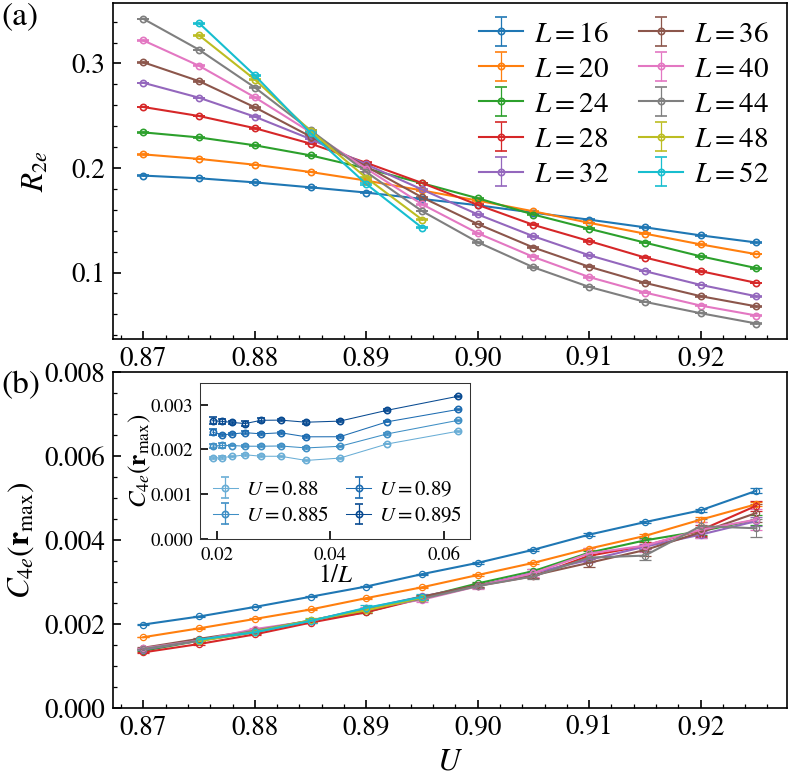

In [4]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42})
for axis in ("xtick", "ytick"):
    plt.rcParams.update({axis + ".direction": "in", axis + ".major.size": 4,
                         axis + ".minor.size": 2, axis + ".major.width": .8,
                         axis + ".minor.width": .6})

from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig = plt.figure(figsize=(5.8, 6.1))
gs = GridSpec(2, 1, figure=fig, width_ratios=[1.5], wspace=.1, hspace=.1)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
for ax, points, line_error_width, marker_width in [
        (ax1, pair_points, .6, .8), (ax2, quartet_points, .5, .6)]:
    for L, group in points.groupby("L", sort=True):
        ax.errorbar(group["U"], group["value"], yerr=group["stderr"],
                    fmt="o-", mfc="none", ms=3, lw=1, capsize=3,
                    elinewidth=line_error_width, capthick=.8,
                    markeredgewidth=marker_width, label=rf"$L={L}$")
    ax.tick_params(labelsize=13)
    ax.minorticks_on()
    for spine in ax.spines.values(): spine.set_linewidth(.8)
ax1.legend(ncols=2, fontsize=14, frameon=False, handlelength=1.5,
           columnspacing=1, handletextpad=.4, borderpad=.1, labelspacing=.3)
ax1.set_ylabel(r"$R_{2e}$", fontsize=15, labelpad=10)
ax2.set_xlabel(r"$U$", fontsize=15)
ax2.set_ylabel(r"$C_{4e}(\mathbf{r}_\text{max})$", fontsize=15)
ax2.set_ylim(0, .008)
axins = inset_axes(ax2, width="40%", height="48%", loc="upper left", borderpad=0,
                   bbox_to_anchor=(.13, 0, 1, .97), bbox_transform=ax2.transAxes)
for U, color in zip([.88, .885, .89, .895], plt.cm.Blues(np.linspace(.5, .9, 4))):
    group = quartet_inset_points[np.isclose(quartet_inset_points["U"], U, rtol=0, atol=1e-12)].sort_values("L")
    axins.errorbar(group["inverse_L"], group["value"], yerr=group["stderr"],
                   marker="o", ms=3, lw=.5, mfc="none", capsize=2,
                   label=rf"$U = {U}$", color=color, elinewidth=.6,
                   capthick=.8, markeredgewidth=.8)
axins.legend(frameon=False, fontsize=10, ncols=2, handlelength=1.2,
             handletextpad=.4, borderpad=.1, labelspacing=.3, columnspacing=.8)
axins.set_xlabel(r"$1/L$", fontsize=12, labelpad=0)
axins.set_ylabel(r"$C_{4e}(\mathbf{r}_\text{max})$", fontsize=12, labelpad=-1)
axins.tick_params(labelsize=9)
axins.yaxis.tick_left()
axins.yaxis.set_label_position("left")
axins.set_ylim(0, .0035)
for spine in axins.spines.values():
    spine.set_color(".2")
    spine.set_linewidth(.5)
for ax, letter in [(ax1, "a"), (ax2, "b")]:
    ax.annotate(f"({letter})", xy=(-.165, .94), xycoords="axes fraction", fontsize=16)
fig.savefig("figures/Fig2.pdf", bbox_inches="tight", pad_inches=.01)
fig.savefig("figures/Fig2.png", dpi=150, bbox_inches="tight", pad_inches=.01)
plt.show()
plt.close(fig)

### S7: interflavor particle-hole correlation ratio


In [5]:
hop_points = eighth[eighth["observable"] == "Rphi"]
display_table(hop_points[["L", "U", "value", "stderr"]].head(8))

L,U,value,stderr
16,0.870,0.015153,0.000003
16,0.875,0.014706,0.000004
16,0.880,0.014246,0.000005
16,0.885,0.013778,0.000003
16,0.890,0.013308,0.000004
16,0.895,0.012826,0.000003
16,0.900,0.012365,0.000004
16,0.905,0.011895,0.000003


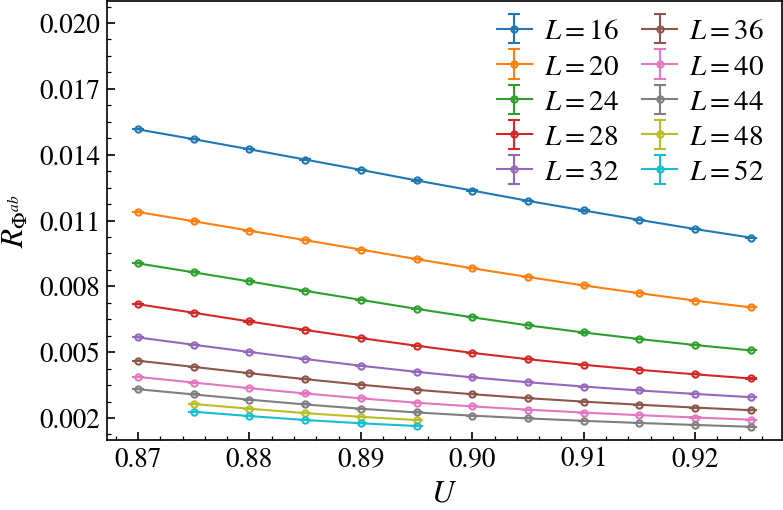

In [6]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42})
for axis in ("xtick", "ytick"):
    plt.rcParams.update({axis + ".direction": "in", axis + ".major.size": 4,
                         axis + ".minor.size": 2, axis + ".major.width": .8,
                         axis + ".minor.width": .6})

fig, ax = plt.subplots(figsize=(5.8, 3.8))
for L, group in hop_points.groupby("L", sort=True):
    ax.errorbar(group["U"], group["value"], yerr=group["stderr"],
                fmt="o-", mfc="none", ms=3, lw=1, capsize=3, label=rf"$L={L}$")
ax.legend(ncols=2, fontsize=14, frameon=False, handlelength=1.2,
          handletextpad=.4, borderpad=.1, labelspacing=.3, columnspacing=.8)
ax.set_xlabel(r"$U$", fontsize=15)
ax.set_ylabel(r"$R_{\Phi^{ab}}$", fontsize=15)
ax.tick_params(labelsize=13)
ax.set_ylim(.001, .021)
ax.set_yticks([.002, .005, .008, .011, .014, .017, .020])
for spine in ax.spines.values(): spine.set_linewidth(.8)
ax.minorticks_on()
fig.savefig("figures/FigS7.pdf", bbox_inches="tight", pad_inches=.01)
fig.savefig("figures/FigS7.png", dpi=150, bbox_inches="tight", pad_inches=.01)
plt.show()
plt.close(fig)

### Fig. 3 and S6: finite-size extrapolation

Fits use the tabulated uncertainties as diagonal absolute-sigma weights:

$$X(L_{\rm eff})=a+bL_{\rm eff}^{-p},\qquad
L_{\rm eff}=\sqrt{L_1L_2}.$$

Full intercept/amplitude covariance gives the fitted-mean error. The gray
region is the envelope of fitted means $\pm1\sigma$ over the stated powers
and size families, rather than a confidence band from one common fit.


In [7]:
eighth_exponents = pd.read_csv("data/scalar_exponents.csv", float_precision="round_trip")
eighth_exponents["L_eff"] = np.sqrt(eighth_exponents["L1"] * eighth_exponents["L2"])
eighth_exponents["DeltaL"] = eighth_exponents["L2"] - eighth_exponents["L1"]
eighth_fit_points = eighth_exponents[eighth_exponents["L_eff"] >= 32]
display_table(eighth_fit_points[["L1", "L2", "DeltaL", "L_eff", "U_cross",
                            "U_cross_stderr", "nu", "nu_stderr", "eta", "eta_stderr"]])

L1,L2,DeltaL,L_eff,U_cross,U_cross_stderr,nu,nu_stderr,eta,eta_stderr
32,40,8,35.777088,0.887922,0.000168,0.572067,0.023193,0.849227,0.003204
36,44,8,39.799497,0.887540,0.000163,0.620531,0.029138,0.844936,0.003571
40,48,8,43.817805,0.885867,0.000167,0.581340,0.027320,0.837056,0.004383
44,52,8,47.833043,0.884072,0.000232,0.627461,0.037589,0.826439,0.006471
28,40,12,33.466401,0.888146,0.000116,0.537791,0.015930,0.851307,0.001960
32,44,12,37.523326,0.887520,0.000103,0.600282,0.012799,0.847178,0.002080
36,48,12,41.569219,0.886647,0.000115,0.592964,0.019582,0.841281,0.002891
40,52,12,45.607017,0.885001,0.000158,0.609465,0.027557,0.832592,0.004154
28,44,16,35.099858,0.887797,0.000078,0.561181,0.012035,0.849453,0.001415
32,48,16,39.191836,0.886892,0.000083,0.595704,0.012021,0.844109,0.001871


In [8]:
def fixed_power_fit(points, observable, power):
    L = points["L_eff"].to_numpy()
    y, error = points[observable].to_numpy(), points[observable + "_stderr"].to_numpy()
    X = np.column_stack([np.ones(len(L)), L ** (-power)])
    Xw = X / error[:, None]
    covariance = np.linalg.inv(Xw.T @ Xw)
    a, b = np.linalg.solve(Xw.T @ Xw, Xw.T @ (y / error))
    sigma = np.sqrt(covariance[0, 0])
    return {"power": power, "intercept": a, "stderr": sigma, "amplitude": b,
            "covariance": covariance, "low": a - sigma, "high": a + sigma}

def fitted_mean(fit, inverse_L):
    t = np.asarray(inverse_L) ** fit["power"]
    C = fit["covariance"]
    mean = fit["intercept"] + fit["amplitude"] * t
    error = np.sqrt(np.maximum(C[0, 0] + 2 * t * C[0, 1] + t**2 * C[1, 1], 0))
    return mean, error

def power_scan(points, observable, powers, inverse_L):
    fits = [fixed_power_fit(points, observable, p) for p in powers]
    for key, sign in [("low", 1), ("high", -1)]:
        i = min(range(len(powers)), key=lambda j: sign * fits[j][key])
        if 0 < i < len(powers) - 1:
            result = minimize_scalar(
                lambda p: sign * fixed_power_fit(points, observable, p)[key],
                bounds=(powers[i - 1], powers[i + 1]), method="bounded",
                options={"xatol": 1e-12})
            fits.append(fixed_power_fit(points, observable, result.x))
    lower, upper = np.full_like(inverse_L, np.inf), np.full_like(inverse_L, -np.inf)
    for fit in fits:
        mean, error = fitted_mean(fit, inverse_L)
        lower, upper = np.minimum(lower, mean - error), np.maximum(upper, mean + error)
    return {"low": min(f["low"] for f in fits), "high": max(f["high"] for f in fits),
            "lower": lower, "upper": upper, "fits": fits}

In [9]:
omega = .758
inverse_Leff = np.linspace(0, 1 / 32, 601)
exponent_powers = np.unique(np.r_[np.linspace(.5, 2, 2001), omega, 1.])
crossing_powers = np.linspace(1, 2, 2001)
eighth_scans, eighth_fixed = {}, {}
fit_summary = []
for observable in ["U_cross", "nu", "eta"]:
    for delta in [8, 12, 16, 20]:
        selected = eighth_fit_points[eighth_fit_points["DeltaL"] == delta]
        powers = crossing_powers if observable == "U_cross" else exponent_powers
        scan = power_scan(selected, observable, powers, inverse_Leff)
        eighth_scans[observable, delta] = scan
        if observable == "U_cross":
            center = (scan["low"] + scan["high"]) / 2
        else:
            fit = fixed_power_fit(selected, observable, omega)
            eighth_fixed[observable, delta] = fit
            center = fit["intercept"]
        fit_summary.append({"observable": observable, "DeltaL": delta,
                            "n_fit_points": len(selected), "representative": center,
                            "envelope_low": scan["low"], "envelope_high": scan["high"]})
display_table(pd.DataFrame(fit_summary))

observable,DeltaL,n_fit_points,representative,envelope_low,envelope_high
U_cross,8,4,0.877058,0.873208,0.880909
U_cross,12,4,0.880104,0.877358,0.882850
U_cross,16,3,0.879939,0.877121,0.882757
U_cross,20,3,0.876646,0.872648,0.880643
nu,8,4,0.761376,0.578940,1.114186
nu,12,4,0.900710,0.663632,1.237070
nu,16,3,0.942603,0.666592,1.342400
nu,20,3,0.861856,0.639226,1.168942
eta,8,4,0.750388,0.661458,0.818472
eta,12,4,0.775045,0.714007,0.825436


### Fig. 3

Panel (a) uses the fixed display parameters
$\widetilde U_c=.88956$ and $1/\widetilde\nu=1.360$.
Panels (b,c) display all six $\Delta L=16$ points against
$L_{\rm eff}^{-.758}$, while the fixed-power line uses only the three pairs
with $L_{\rm eff}\ge32$. Diamonds show the fixed-power intercepts without
error bars. Gray envelopes combine all four size families and $p\in[.5,2]$.


In [10]:
collapse_points = pair_points.copy()
collapse_points["scaled_U"] = (collapse_points["U"] - .88956) * collapse_points["L"]**1.360
display_table(collapse_points[["L", "U", "scaled_U", "value", "stderr"]].head(6))

L,U,scaled_U,value,stderr
16,0.870,-0.849126,0.192746,0.000166
16,0.875,-0.632069,0.190160,0.000127
16,0.880,-0.415012,0.186249,0.000139
16,0.885,-0.197956,0.181507,0.000172
16,0.890,0.019101,0.176493,0.000274
16,0.895,0.236158,0.170404,0.000143


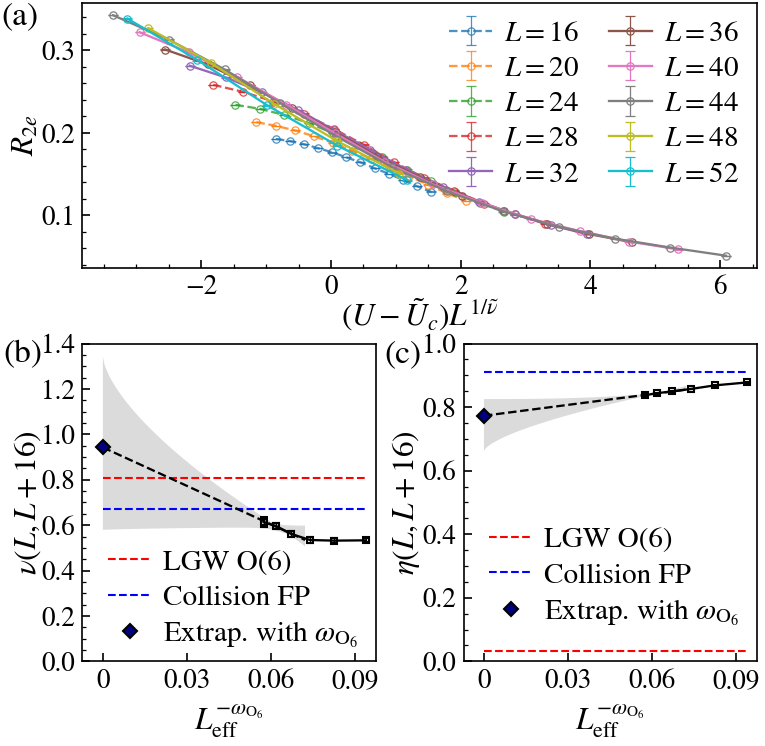

In [11]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42})
for axis in ("xtick", "ytick"):
    plt.rcParams.update({axis + ".direction": "in", axis + ".major.size": 4,
                         axis + ".minor.size": 2, axis + ".major.width": .8,
                         axis + ".minor.width": .6})

from matplotlib.transforms import Bbox

fig = plt.figure(figsize=(5.8, 5.7))
gs = GridSpec(2, 2, height_ratios=[1, 1.2], hspace=.26, wspace=.3)
ax1, ax3, ax2 = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
for L, group in collapse_points.groupby("L", sort=True):
    ax1.errorbar(group["scaled_U"], group["value"], yerr=group["stderr"],
                 fmt="o", linestyle="--" if L < 32 else "-", alpha=.8 if L < 32 else 1,
                 ms=3.5, mfc="none", lw=1.1, capsize=2.5, elinewidth=.6,
                 capthick=.8, markeredgewidth=.6, label=rf"$L={L}$")
ax1.legend(ncols=2, fontsize=14, frameon=False, handlelength=1.5,
           columnspacing=1, handletextpad=.4, borderpad=.1, labelspacing=.3)
ax1.set_ylabel(r"$R_{2e}$", fontsize=15, labelpad=0)
collapse_label = r"$(U-\tilde{U}_c)L^{1/\tilde{\nu}}$"
ax1.set_xlabel(collapse_label, fontsize=15, labelpad=-2)
ax1.tick_params(labelsize=13)
selected = eighth_exponents[eighth_exponents["DeltaL"] == 16]
right = ((1 / 15) / np.sqrt(1 + 16 / 15))**omega
reference_extent = ((1 / 16) / np.sqrt(2))**omega
for ax, observable, theory_o6, theory_collision, labelpad in [
        (ax3, "nu", 1 / 1.2375, .67, -1), (ax2, "eta", .03157, .91, 0)]:
    ax.errorbar(selected["L_eff"]**(-omega), selected[observable],
                yerr=selected[observable + "_stderr"], marker="s", mfc="none", ms=3,
                capsize=2, color="k", lw=1.1, elinewidth=.6)
    ax.hlines(theory_o6, 0, reference_extent, ls="--", color="r", lw=1, label="LGW O(6)")
    ax.hlines(theory_collision, 0, reference_extent, ls="--", color="b", lw=1, label="Collision FP")
    fit = eighth_fixed[observable, 16]
    ax.plot(0, fit["intercept"], marker="D", linestyle="none", color="k", mfc="navy", ms=5,
            label=r"Extrap. with $\omega_{\mathrm{O}_6}$", zorder=3)
    lower = np.minimum.reduce([eighth_scans[observable, d]["lower"] for d in [8, 12, 16, 20]])
    upper = np.maximum.reduce([eighth_scans[observable, d]["upper"] for d in [8, 12, 16, 20]])
    ax.fill_between(inverse_Leff**omega, lower, upper, facecolor="#808080", alpha=.28,
                    edgecolor="none", linewidth=0, zorder=.1)
    mean, _ = fitted_mean(fit, inverse_Leff)
    ax.plot(inverse_Leff**omega, mean, color="k", linestyle="--", lw=1.1, zorder=2.1)
    ax.set_xlim(-.005 / (1 / 15) * right, right)
    ax.set_ylim(0, 1.4 if observable == "nu" else 1)
    if observable == "nu": ax.set_yticks(np.arange(0, 1.41, .2))
    ax.set_xticks([0, .03, .06, .09], ["0", "0.03", "0.06", "0.09"])
    ax.set_xlabel(r"$L_{\mathrm{eff}}^{-\omega_{\mathrm{O}_6}}$", fontsize=15)
    ax.set_ylabel(rf"$\{observable}(L, L + 16)$", fontsize=15, labelpad=labelpad)
    ax.tick_params(labelsize=13)
    ax.legend(frameon=False, fontsize=14, loc="lower right",
              bbox_to_anchor=(1, -.02) if observable == "nu" else (1, .05),
              handlelength=1.5, columnspacing=1, handletextpad=.4, borderpad=.1, labelspacing=.3)
    ax.minorticks_on()
    ax.xaxis.set_minor_locator(plt.NullLocator())
ax1.annotate("(a)", xy=(-.12, .92), xycoords="axes fraction", fontsize=16)
for ax, letter in [(ax3, "b"), (ax2, "c")]:
    ax.annotate(f"({letter})", xy=(-.27, .94), xycoords="axes fraction", fontsize=16)
for ax in [ax1, ax2, ax3]:
    for spine in ax.spines.values(): spine.set_linewidth(.8)
ax1.minorticks_on()
fig3_crop = Bbox.from_bounds(.1756, .06278993055555554, 5.101256897223611, 4.973663839725)
fig.savefig("figures/Fig3.pdf", bbox_inches=fig3_crop, pad_inches=0)
fig.savefig("figures/Fig3.png", dpi=150, bbox_inches=fig3_crop, pad_inches=0)
plt.show()
plt.close(fig)

### S6: separate size-family extrapolations

All finite-size points are shown. Dashed curves use $\omega=.758$ for
$\nu,\eta$; their intercept error bars retain the asymmetric endpoints of
the full power-scan envelope. For $U_c$, the representative point and dashed
curve are the midpoint of the $q\in[1,2]$ envelope.

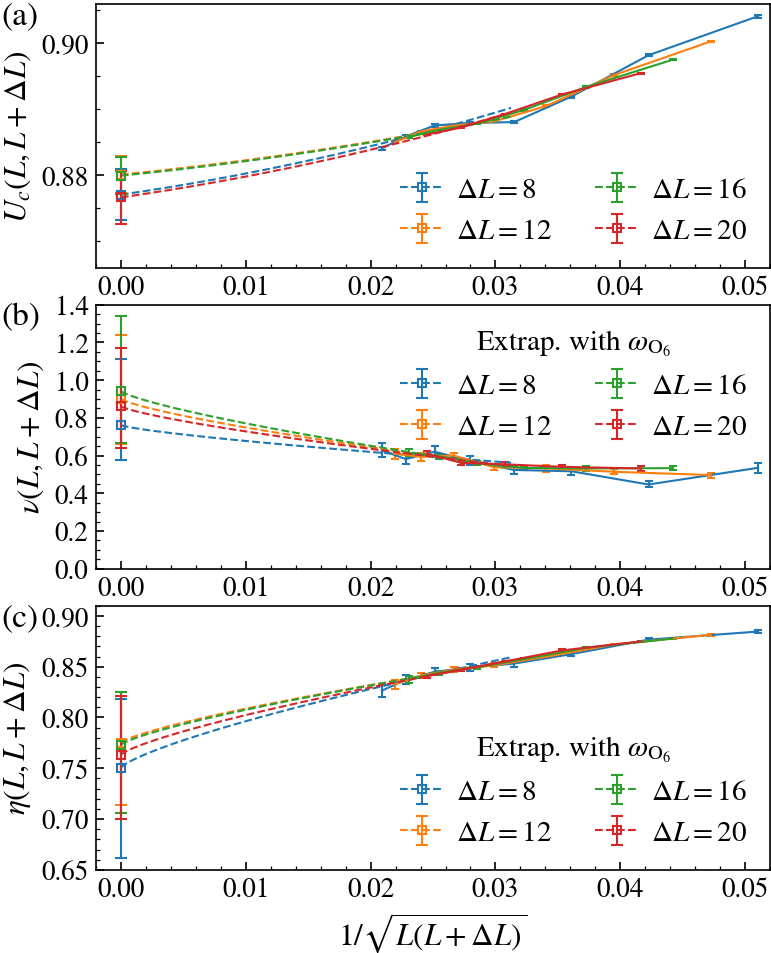

In [12]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42})
for axis in ("xtick", "ytick"):
    plt.rcParams.update({axis + ".direction": "in", axis + ".major.size": 4,
                         axis + ".minor.size": 2, axis + ".major.width": .8,
                         axis + ".minor.width": .6})

fig, axes = plt.subplots(3, 1, figsize=(5.8, 7.5))
fig.subplots_adjust(hspace=.14)
for ax, observable, letter in zip(axes, ["U_cross", "nu", "eta"], "abc"):
    handles = []
    for index, delta in enumerate([8, 12, 16, 20]):
        color = plt.cm.tab10.colors[index]
        points = eighth_exponents[eighth_exponents["DeltaL"] == delta]
        ax.errorbar(1 / points["L_eff"], points[observable], yerr=points[observable + "_stderr"],
                    capsize=2, lw=1, color=color)
        scan = eighth_scans[observable, delta]
        if observable == "U_cross":
            mean = (scan["lower"] + scan["upper"]) / 2
            center = (scan["low"] + scan["high"]) / 2
        else:
            fit = eighth_fixed[observable, delta]
            mean, _ = fitted_mean(fit, inverse_Leff)
            center = fit["intercept"]
        ax.plot(inverse_Leff, mean, color=color, ls="--", lw=1, zorder=2.1)
        handle = ax.errorbar(0, center, yerr=[[center - scan["low"]], [scan["high"] - center]],
                             fmt="s", linestyle="--", capsize=3, color=color, mfc="none", ms=4,
                             elinewidth=1, lw=1, label=rf"$\Delta L={delta}$", zorder=3)
        handles.append(handle)
    ax.set_xlim(-.002, .052)
    ax.set_ylim(*{"U_cross": (.866, .906), "nu": (0, 1.4), "eta": (.65, .91)}[observable])
    if observable == "nu": ax.set_yticks(np.arange(0, 1.41, .2))
    if observable == "eta": ax.set_yticks(np.arange(.65, .901, .05))
    ax.set_ylabel({"U_cross": r"$U_c(L,L+\Delta L)$", "nu": r"$\nu(L,L+\Delta L)$",
                   "eta": r"$\eta(L,L+\Delta L)$"}[observable], fontsize=15)
    ax.tick_params(labelsize=13, direction="in", which="both")
    ax.legend(handles=handles, frameon=False, fontsize=14,
              loc="upper right" if observable == "nu" else "lower right", ncols=2,
              handlelength=1.5, columnspacing=1.5, handletextpad=.4, borderpad=.3, labelspacing=.5,
              title=None if observable == "U_cross" else r"Extrap. with $\omega_{\mathrm{O}_6}$",
              title_fontsize=14)
    ax.annotate(f"({letter})", xy=(-.14, .925), xycoords="axes fraction", fontsize=16)
    ax.minorticks_on()
    for spine in ax.spines.values(): spine.set_linewidth(.8)
axes[-1].set_xlabel(r"$1/\sqrt{L(L+\Delta L)}$", fontsize=15)
s6_crop = Bbox.from_bounds(.0857, .2705121527777778, 5.1443, 6.359130250677778)
fig.savefig("figures/FigS6.pdf", bbox_inches=s6_crop, pad_inches=0)
fig.savefig("figures/FigS6.png", dpi=150, bbox_inches=s6_crop, pad_inches=0)
plt.show()
plt.close(fig)

## Figure 5: bridge benchmark and real-space correlations

The real-space plot omits the onsite point and retains repeated radii.


In [13]:
benchmark = pd.read_csv("data/fig5_benchmark.csv")
quartet = pd.read_csv("data/fig5_real_space.csv")
benchmark_groups = {
    (observable, method): group.sort_values("U")
    for (observable, method), group in benchmark.groupby(["observable", "method"])
}
quartet_plot = quartet.loc[quartet["distance"].gt(0)]

display_table(benchmark[["method", "U", "observable", "value", "error"]])
display_table(quartet[["U", "point_index", "distance", "value", "error"]].head())
display_table(pd.DataFrame({
    "table": ["benchmark", "real-space correlations"],
    "rows": [len(benchmark), len(quartet)],
    "plotted_rows": [len(benchmark), len(quartet_plot)],
}))


method,U,observable,value,error
no_bridge,0.75,S2e_0,1.949730,4.172374e-06
no_bridge,0.75,C4e_rmax,0.000721,9.538048e-07
no_bridge,0.80,S2e_0,1.957824,4.911666e-06
no_bridge,0.80,C4e_rmax,0.000979,2.234197e-06
no_bridge,0.85,S2e_0,1.966688,5.566139e-06
...,...,...,...,...
ED,1.35,C4e_rmax,0.066115,0.000000e+00
ED,1.40,S2e_0,1.977952,0.000000e+00
ED,1.40,C4e_rmax,0.075023,0.000000e+00
ED,1.45,S2e_0,1.962881,0.000000e+00


U,point_index,distance,value,error
0.87,0,0.000000,1.341922,0.000030
0.87,1,1.000000,0.017331,0.000019
0.87,2,1.000000,0.017290,0.000020
0.87,3,1.414214,0.010955,0.000012
0.87,4,2.000000,0.005038,0.000017


table,rows,plotted_rows
benchmark,120,120
real-space correlations,363,360


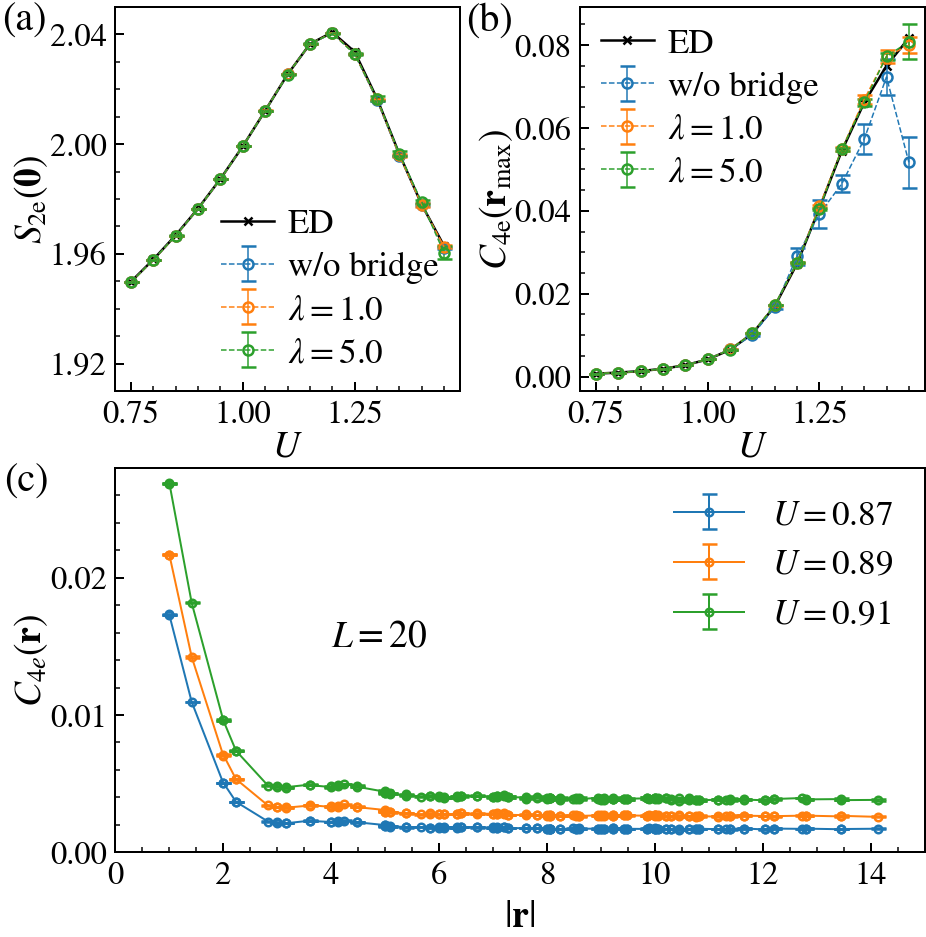

In [14]:
from matplotlib.gridspec import GridSpec

with plt.rc_context():
    plt.rcdefaults()
    plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix"})
    fig = plt.figure(figsize=(5.8, 6.1))
    fs = 15
    gs = GridSpec(2, 2, height_ratios=[1, 1.0], hspace=0.20, wspace=0.35)
    ax2 = fig.add_subplot(gs[0, :1])
    ax1 = fig.add_subplot(gs[0, 1:])
    ax3 = fig.add_subplot(gs[1, :])
    plt.subplots_adjust(wspace=0.36, hspace=0.0)

    ax1.set_xlabel(r"$U$", fontsize=fs, labelpad=0)
    ax2.set_xlabel(r"$U$", fontsize=fs, labelpad=0)
    ax1.set_ylabel(r"$C_\text{4e}(\mathbf{r}_\text{max})$", fontsize=fs, labelpad=0)
    ax2.set_ylabel(r"$S_\text{2e}(\mathbf{0})$", fontsize=fs, labelpad=0)

    for ax, observable in [(ax1, "C4e_rmax"), (ax2, "S2e_0")]:
        ed = benchmark_groups[(observable, "ED")]
        ax.plot(ed["U"], ed["value"], "kx-", lw=1, ms=3, label="ED")
        for method, label in [
            ("no_bridge", "w/o bridge"),
            ("bridge_1.0", r"$\lambda=1.0$"),
            ("bridge_5.0", r"$\lambda=5.0$"),
        ]:
            points = benchmark_groups[(observable, method)]
            ax.errorbar(points["U"], points["value"], yerr=points["error"],
                        fmt="o--", mfc="none", lw=0.6, capsize=3, ms=4, label=label)

    for ax in [ax1, ax2]:
        ax.legend(frameon=False, fontsize=14, handlelength=1.5, columnspacing=1.0,
                  handletextpad=0.4, borderpad=0.1, labelspacing=0.3)
        ax.tick_params(labelsize=13, direction="in", which="both")
    ax2.set_ylim(1.91, 2.05)

    for u in [0.87, 0.89, 0.91]:
        points = quartet_plot.loc[np.isclose(quartet_plot["U"], u)].sort_values("point_index")
        ax3.errorbar(points["distance"], points["value"], yerr=points["error"],
                     fmt="o-", mfc="none", capsize=3, lw=0.8, ms=3, label=f"$U={u}$")
    ax3.legend(frameon=False, fontsize=14)
    ax3.set_xlabel(r"$\vert\mathbf{r}\vert$", fontsize=15)
    ax3.set_ylabel(r"$C_{4e}(\mathbf{r})$", fontsize=15, labelpad=0)
    ax3.set_ylim(0, 0.028)
    ax3.set_xlim(0, 15)
    ax3.tick_params(labelsize=13, direction="in", which="both")
    for ax in [ax1, ax2, ax3]:
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
    ax3.text(4, 0.015, r"$L=20$", fontsize=15)
    ax2.set_yticks([1.92, 1.96, 2.0, 2.04])
    loc_x, loc_y = -0.33, 0.94
    ax1.annotate("(b)", xy=(loc_x, loc_y), xycoords="axes fraction", fontsize=16)
    ax2.annotate("(a)", xy=(loc_x, loc_y), xycoords="axes fraction", fontsize=16)
    ax3.annotate("(c)", xy=(loc_x/2+0.027, loc_y), xycoords="axes fraction", fontsize=16)
    ax1.minorticks_on()
    ax2.minorticks_on()
    ax3.minorticks_on()

    for extension in ["pdf", "png"]:
        fig.savefig(f"figures/Fig5.{extension}", dpi=180, bbox_inches="tight", pad_inches=0.01)
    plt.show()
    plt.close(fig)


## Figure S8: Green functions and the single-particle gap

Load the tabulated Green functions, gap estimates, and their reported errors.
The finite-size gap estimates are used for the two infinite-size extrapolations.


In [15]:
green_csv = pd.read_csv("data/s8_green.csv", float_precision="round_trip")
gap_csv = pd.read_csv("data/s8_gap.csv", float_precision="round_trip")
gap_sizes = sorted(green_csv["L"].unique())
gap_tau = np.sort(green_csv["tau"].unique())
gap_u = np.sort(green_csv["U"].unique())
gap_green_mean, gap_green_error = {}, {}
for L in gap_sizes:
    points = green_csv.loc[green_csv["L"].eq(L)].sort_values(["U", "tau"])
    shape = (len(gap_u), len(gap_tau))
    gap_green_mean[L] = points["value"].to_numpy().reshape(shape)
    gap_green_error[L] = points["error"].to_numpy().reshape(shape)

gap_csv_finite = gap_csv.loc[np.isfinite(pd.to_numeric(gap_csv["L"]))].copy()
gap_csv_finite["L"] = gap_csv_finite["L"].astype(int)
gap_by_size = {}
for L in gap_sizes:
    points = gap_csv_finite.loc[gap_csv_finite["L"].eq(L)].sort_values("U")
    gap_by_size[L] = (points["value"].to_numpy(), points["error"].to_numpy())
display_table(green_csv[["L", "U", "tau", "value", "error"]].head())
display_table(gap_csv_finite[["L", "U", "value", "error"]])


L,U,tau,value,error
16,0.81,0.0,0.330719,5.551115e-17
16,0.81,0.1,0.270001,3.359950e-05
16,0.81,0.2,0.224722,3.691559e-05
16,0.81,0.3,0.190252,3.172966e-05
16,0.81,0.4,0.163530,3.708700e-05


L,U,value,error
16,0.81,0.178152,0.000286
16,0.82,0.187238,0.000342
16,0.83,0.198539,0.000375
16,0.84,0.210454,0.000382
16,0.85,0.224259,0.000416
16,0.86,0.239214,0.000689
16,0.87,0.255374,0.000862
16,0.88,0.277855,0.000733
16,0.89,0.299765,0.000789
16,0.90,0.323571,0.001211


### Extrapolate to infinite size
For each $U$, fit $\Delta(L)=a+cL^{-p}$ with $p=1$ and $2$, using the finite-size gap errors as weights. The covariance is $(X^\mathsf{T}WX)^{-1}$, with absolute uncertainties and no residual-variance rescaling.


In [16]:
def gap_fit(L, y, sigma, power):
    design = np.column_stack([np.ones(len(L)), L ** (-float(power))])
    weighted = design / sigma[:, None]
    covariance = np.linalg.inv(weighted.T @ weighted)
    coefficients = np.linalg.solve(weighted.T @ weighted, weighted.T @ (y / sigma))
    chi2 = np.sum(((y - design @ coefficients) / sigma) ** 2)
    return coefficients, covariance, chi2

gap_fit_rows = []
gap_extrapolation = {}
for power in [1, 2]:
    extrapolated = []
    for ui, u in enumerate(gap_u):
        y = np.array([gap_by_size[L][0][ui] for L in gap_sizes])
        sigma = np.array([gap_by_size[L][1][ui] for L in gap_sizes])
        coefficients, covariance, chi2 = gap_fit(np.asarray(gap_sizes, dtype=float), y, sigma, power)
        a, c = coefficients
        a_error, c_error = np.sqrt(np.diag(covariance))
        extrapolated.append([a, a_error])
        gap_fit_rows.append({
            "U": round(float(u), 2), "power": power, "a": a, "a_error": a_error,
            "c": c, "c_error": c_error, "chi2": chi2, "dof": len(gap_sizes) - 2,
        })
    gap_extrapolation[power] = np.array(extrapolated)

gap_fit_results = pd.DataFrame(gap_fit_rows)
display_table(gap_fit_results)


U,power,a,a_error,c,c_error,chi2,dof
0.81,1,0.116565,0.000396,1.045694,0.009564,1578.158303,3
0.82,1,0.126053,0.000515,1.057326,0.012346,1458.188629,3
0.83,1,0.134069,0.000522,1.091879,0.012392,687.770766,3
0.84,1,0.149370,0.000574,1.019976,0.013707,364.427681,3
0.85,1,0.164843,0.000757,0.980282,0.016686,145.671029,3
0.86,1,0.183222,0.001103,0.929210,0.025383,37.046890,3
0.87,1,0.206791,0.001303,0.788276,0.031034,15.421717,3
0.88,1,0.238662,0.001356,0.627397,0.029645,11.259412,3
0.89,1,0.270575,0.001782,0.461592,0.036743,4.672423,3
0.90,1,0.314981,0.002850,0.137412,0.058471,7.440046,3


### Plot Figure S8


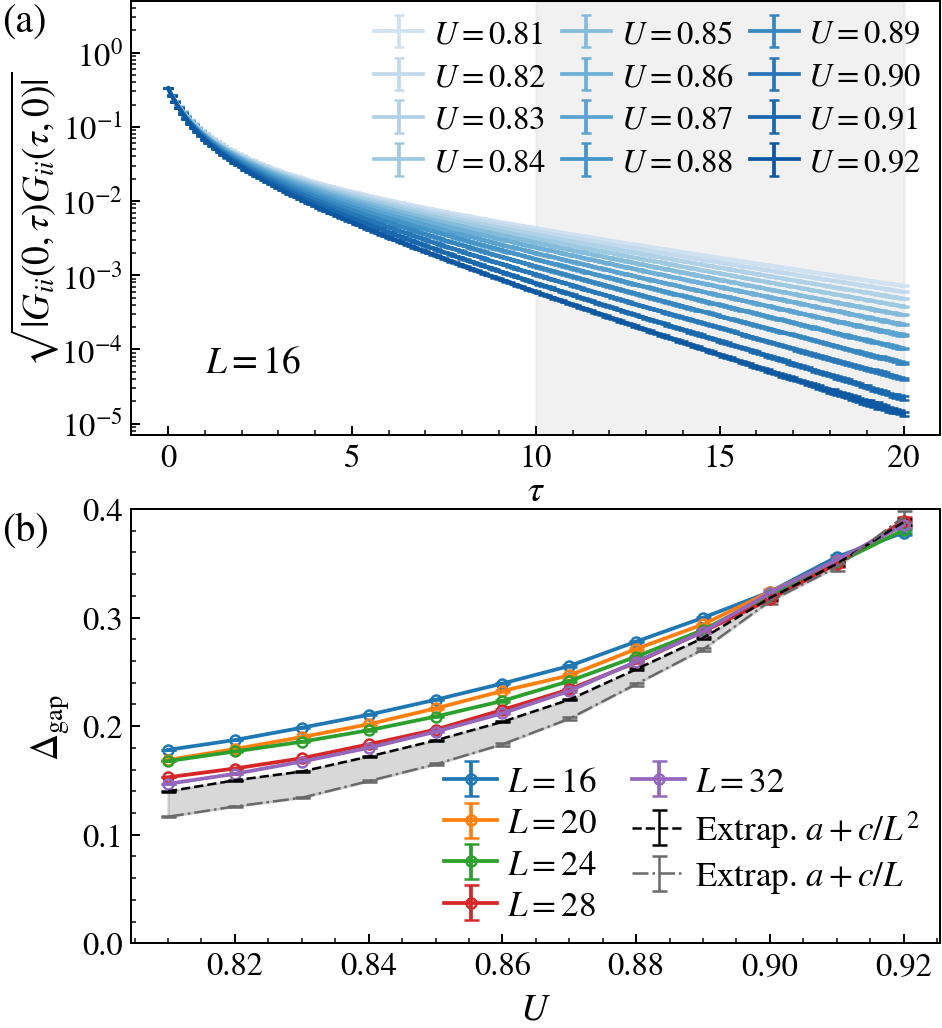

In [17]:
from matplotlib.gridspec import GridSpec

with plt.rc_context():
    plt.rcdefaults()
    plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix"})
    fig = plt.figure(figsize=(5.8, 6.8))
    gs = GridSpec(2, 1, figure=fig, width_ratios=[1.5], wspace=0.1, hspace=0.17)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0])
    fs = 15

    n = 12
    for ui, u in enumerate(gap_u):
        color = plt.cm.Blues(ui / (1.5*n - 1) + 0.2)
        ax1.errorbar(gap_tau, gap_green_mean[16][ui], yerr=gap_green_error[16][ui],
                     capsize=2, color=color, label=f"$U = {u:.2f}$")
    ax1.set_yscale("log")
    ax1.set_xlabel(r"$\tau$", fontsize=fs, labelpad=0)
    ax1.set_ylabel(r"$\sqrt{|G_{ii}(0,\tau)G_{ii}(\tau,0)|}$", fontsize=fs, labelpad=0)
    ax1.legend(frameon=False, ncols=3, fontsize=13, loc="upper right", handlelength=1.5,
               columnspacing=0.5, handletextpad=0.3, borderpad=0.08, labelspacing=0.4)
    ax1.set_ylim(7e-6, 5)
    ax1.text(1, 5e-5, r"$L=16$", fontsize=15)
    ax1.axvspan(10, 20, alpha=0.3, color="lightgrey", label="fit region")

    for L in gap_sizes:
        values, errors = gap_by_size[L]
        ax2.errorbar(gap_u, values, yerr=errors, fmt="o-", ms=4, mfc="none",
                     label=rf"$L={L}$", capsize=3)
    c_list_2, c_err_list_2 = gap_extrapolation[2].T
    c_list, c_err_list = gap_extrapolation[1].T
    ax2.errorbar(gap_u, c_list_2, yerr=c_err_list_2, linestyle="--", linewidth=1,
                 color="black", capsize=3, label=r"Extrap. $a+c/L^2$")
    ax2.errorbar(gap_u, c_list, yerr=c_err_list, linestyle="-.", linewidth=1,
                 color="dimgray", capsize=3, label=r"Extrap. $a+c/L$")
    ax2.fill_between(gap_u, c_list, c_list_2, color="grey", alpha=0.3)
    ax2.set_xlabel(r"$U$", fontsize=fs)
    ax2.set_ylabel(r"$\Delta_\text{gap}$", fontsize=fs)
    ax2.set_ylim(0, 0.40)
    ax2.legend(frameon=False, fontsize=14, ncols=2, handlelength=1.5,
               columnspacing=1.0, handletextpad=0.3, borderpad=0.08, labelspacing=0.25)
    for ax in [ax1, ax2]:
        ax.tick_params(labelsize=13, direction="in", which="both")
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
    ax1.annotate("(a)", xy=(-0.16, 0.93), xycoords="axes fraction", fontsize=16)
    ax2.annotate("(b)", xy=(-0.16, 0.93), xycoords="axes fraction", fontsize=16)
    ax1.minorticks_on()
    ax2.minorticks_on()

    for extension in ["pdf", "png"]:
        fig.savefig(f"figures/FigS8.{extension}", dpi=180, bbox_inches="tight", pad_inches=0.01)
    plt.show()
    plt.close(fig)


## Figure S9: pairing in momentum space

Maps use $L=44$; cuts use every available size at $k_y=0$.
The periodic $+\pi$ endpoint repeats $-\pi$ for display.


In [18]:
s9_data = pd.read_csv("data/s9_value_error.csv", float_precision="round_trip")
display_table(s9_data[["U", "L", "x", "y", "value", "error"]].head())


s9_grid_sizes = s9_data.groupby(["U", "L"], sort=True).size().rename("rows").reset_index()
display_table(s9_grid_sizes)


U,L,x,y,value,error
0.87,16,0.0,0.000,2.368043,0.000473
0.87,16,0.0,0.125,1.911130,0.000096
0.87,16,0.0,0.250,1.777143,0.000052
0.87,16,0.0,0.375,1.694536,0.000042
0.87,16,0.0,0.500,1.631913,0.000027


U,L,rows
0.870,16,256
0.870,20,400
0.870,24,576
0.870,28,784
0.870,32,1024
0.870,36,1296
0.870,40,1600
0.870,44,1936
0.925,16,256
0.925,20,400


In [19]:
# Rebuild the native grid in (ix, iy) order.
s9_points = []
for (u, length), grid in s9_data.groupby(["U", "L"], sort=True):
    grid = grid.sort_values(["ix", "iy"])
    s9_points.append(
        dict(
            plot_U=u,
            L=int(length),
            mean=grid["value"].to_numpy().reshape(length, length),
            error=grid["error"].to_numpy().reshape(length, length),
        )
    )


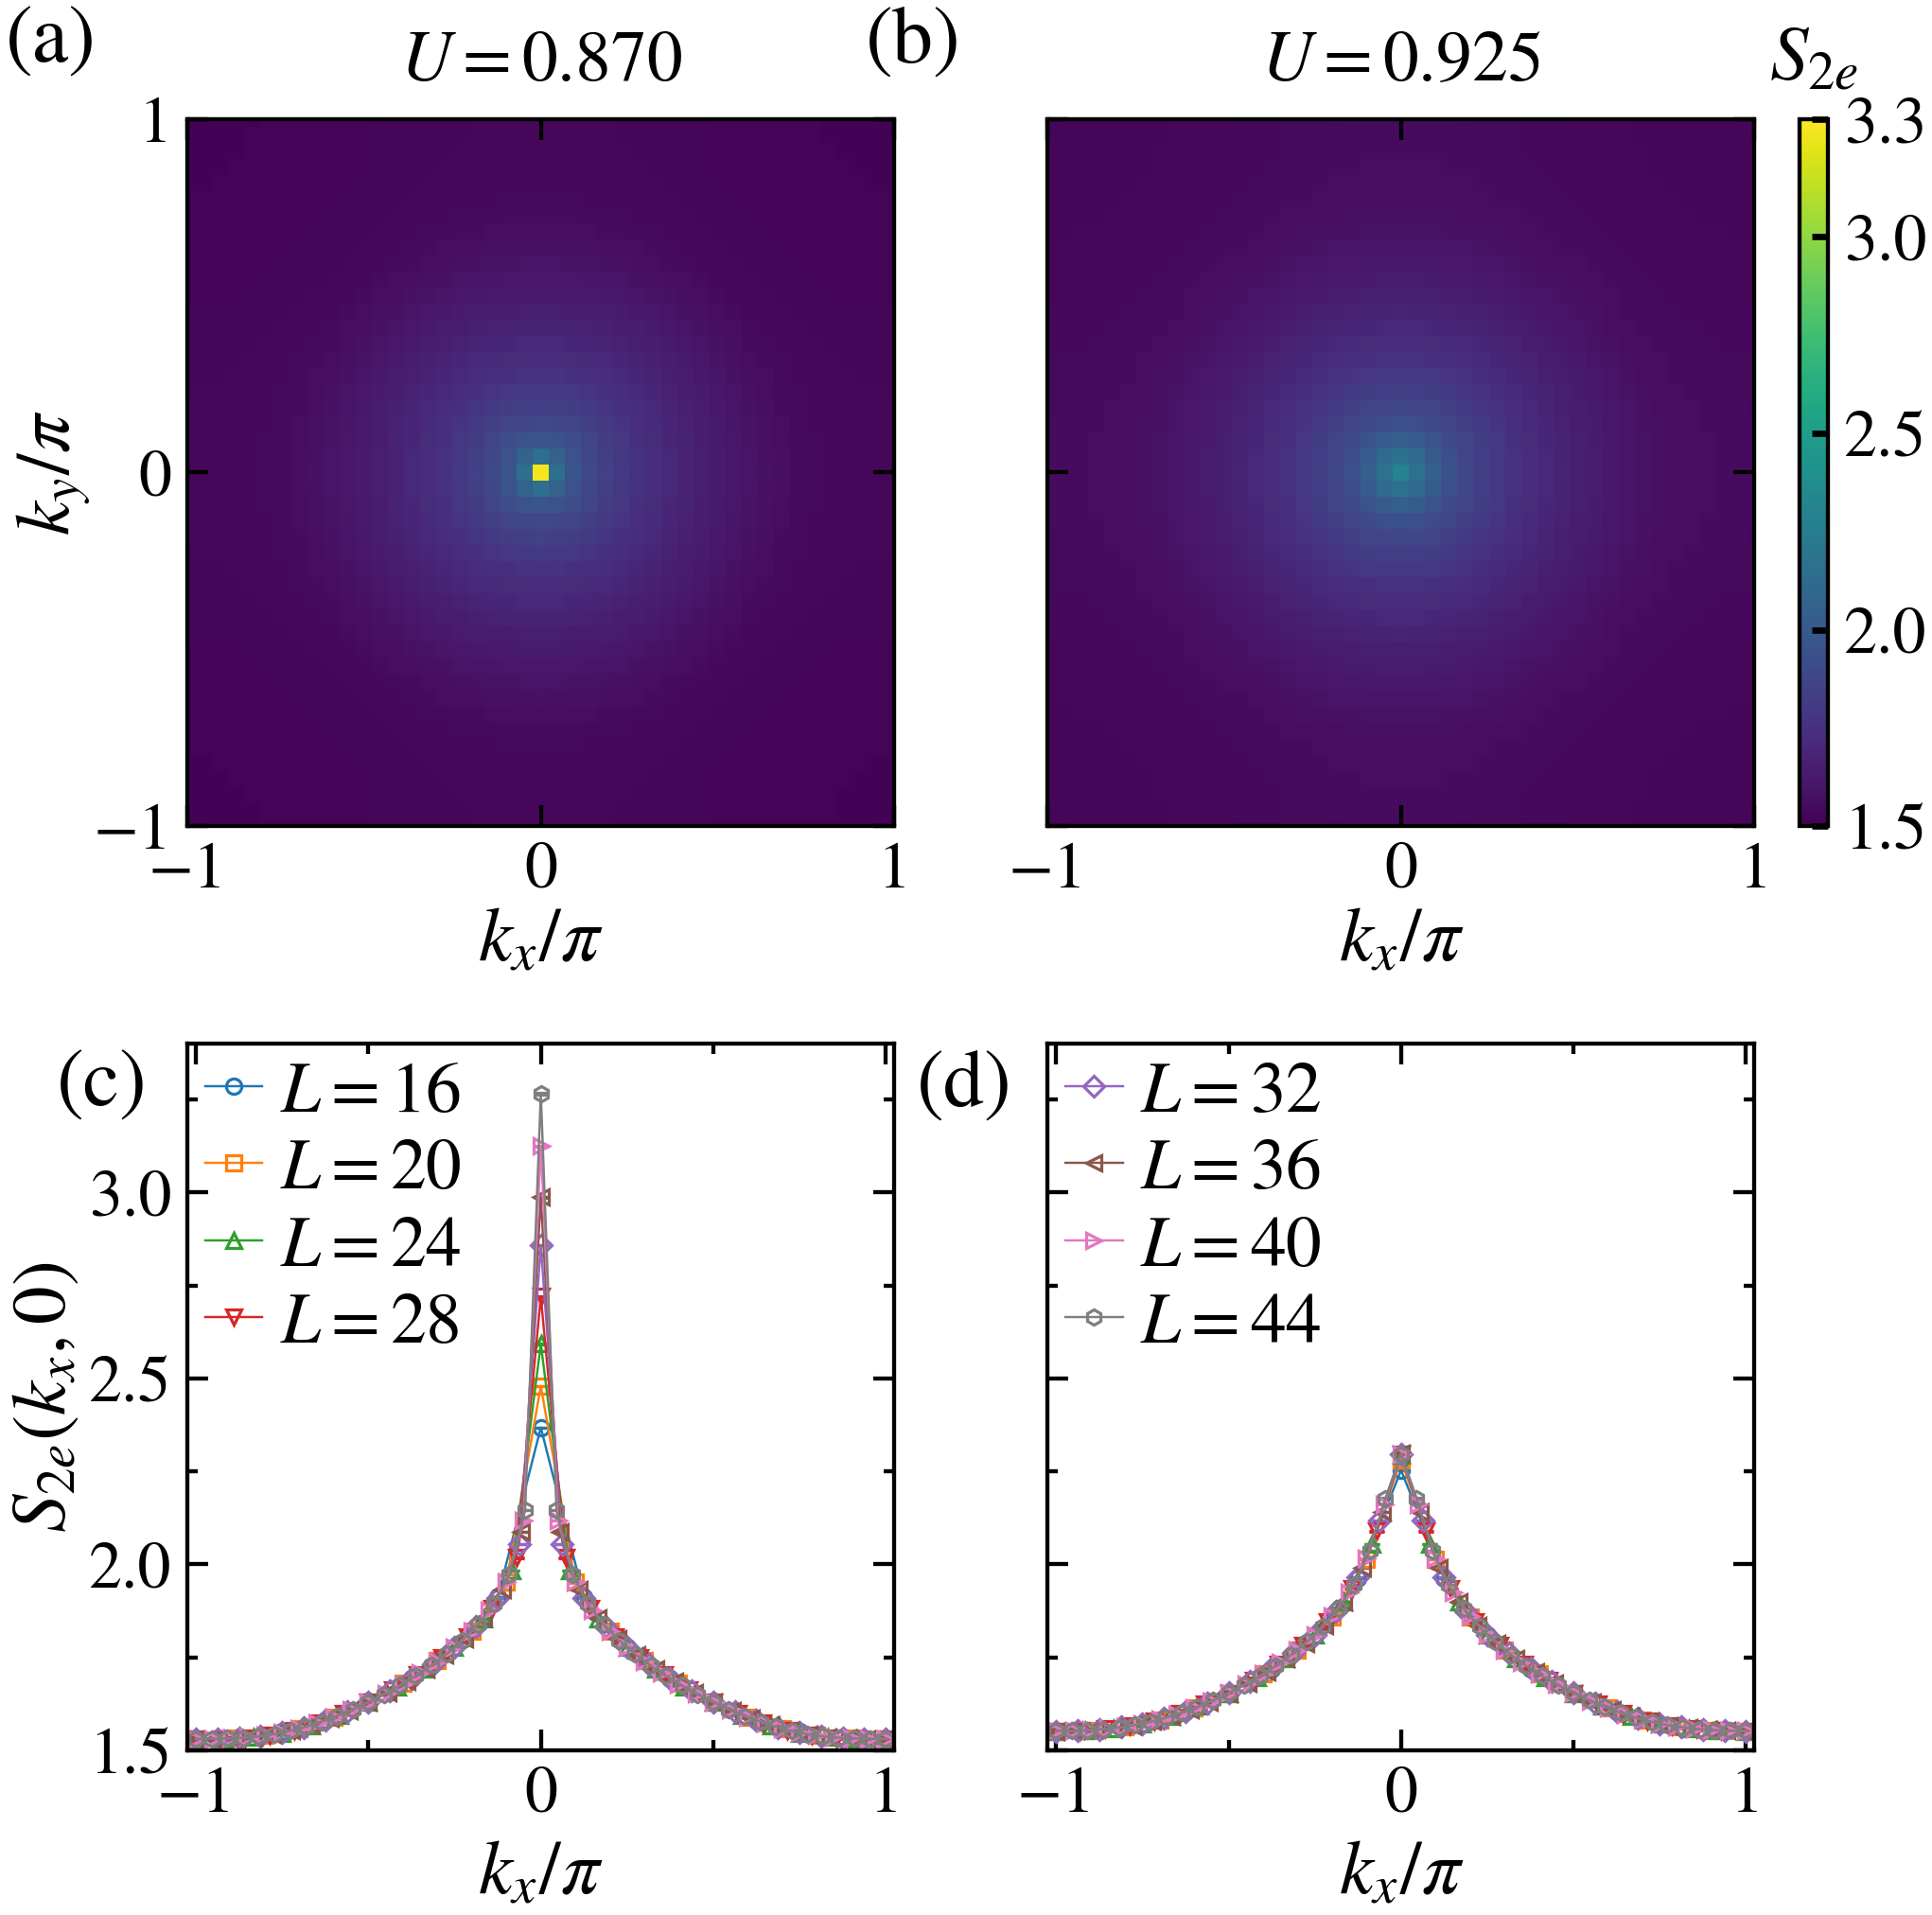

In [20]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator

FIG2_SCALE = 0.64755
FONT = dict(
    axes=15 * FIG2_SCALE, ticks=13 * FIG2_SCALE, legend=14 * FIG2_SCALE, panel=16 * FIG2_SCALE
)
US = (0.87, 0.925)
MARKERS = ("o", "s", "^", "v", "D", "<", ">", "h")
TEX_PT_PER_INCH = 72.27
columnwidth = 246.0
canvas_width = 3.6207249507058186


def s9_axes_style(ax):
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
        width=0.8 * FIG2_SCALE,
        labelsize=FONT["ticks"],
        pad=2,
    )
    ax.tick_params(which="major", length=4 * FIG2_SCALE)
    ax.tick_params(which="minor", length=2 * FIG2_SCALE)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8 * FIG2_SCALE)


plt.rcdefaults()
plt.rcParams.update(
    {
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "text.usetex": False,
        "font.size": FONT["legend"],
        "axes.labelsize": FONT["axes"],
        "axes.titlesize": FONT["legend"],
        "xtick.labelsize": FONT["ticks"],
        "ytick.labelsize": FONT["ticks"],
        "axes.unicode_minus": True,
    }
)
by_u = {
    u: sorted([p for p in s9_points if np.isclose(p["plot_U"], u)], key=lambda p: p["L"])
    for u in US
}
common_sizes = set.intersection(*[{p["L"] for p in by_u[u]} for u in US])
map_size = max(common_sizes)
maps = [next((p for p in by_u[u] if p["L"] == map_size)) for u in US]
sizes = sorted({p["L"] for p in s9_points})
style = {
    size: {"color": plt.cm.tab10.colors[i], "marker": MARKERS[i]} for i, size in enumerate(sizes)
}
lower = np.floor(min((p["mean"].min() for p in maps)) * 10) / 10
upper = np.ceil(max((p["mean"].max() for p in maps)) * 10) / 10
norm = Normalize(vmin=lower, vmax=upper, clip=False)
target_width = columnwidth / TEX_PT_PER_INCH
width = canvas_width
extra_side = (width - target_width) / 2
height = 3.48 + 2 * extra_side
map_bottom = 2.09 + extra_side
fig = plt.figure(figsize=(width, height), facecolor="white")
left, right, gap = (0.43, 0.43, 0.27)
side = (width - left - right - gap) / 2
x_positions = (left, left + side + gap)
map_axes = [
    fig.add_axes([x / width, map_bottom / height, side / width, side / height]) for x in x_positions
]
cut_axes = [
    fig.add_axes([x / width, 0.57 / height, side / width, side / height]) for x in x_positions
]
cax = fig.add_axes(
    [(x_positions[-1] + side + 0.08) / width, map_bottom / height, 0.05 / width, side / height]
)
for i, (ax, p) in enumerate(zip(map_axes, maps)):
    grid_size = len(p["mean"])
    k = np.arange(-grid_size // 2, grid_size // 2 + 1) * 2.0 / grid_size
    values = np.pad(np.fft.fftshift(p["mean"]), ((0, 1), (0, 1)), mode="wrap")
    mesh = ax.pcolormesh(
        k,
        k,
        values.T,
        shading="nearest",
        cmap="viridis",
        norm=norm,
        rasterized=True,
        antialiased=False,
    )
    ax.set(xlim=(-1, 1), ylim=(-1, 1), aspect="equal", xlabel="$k_x/\\pi$")
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_title(f"$U={p['plot_U']:.3f}$", pad=5)
    if i == 0:
        ax.set_ylabel("$k_y/\\pi$", labelpad=0)
    else:
        ax.tick_params(labelleft=False)
    ax.xaxis.labelpad = 1
    s9_axes_style(ax)
colorbar = fig.colorbar(mesh, cax=cax, orientation="vertical")
colorbar.set_ticks([v for v in (1.5, 2.0, 2.5, 3.0, 3.3) if lower <= v <= upper])
colorbar.ax.set_title("$S_{2e}$", pad=5, fontsize=FONT["axes"])
colorbar.ax.tick_params(labelsize=FONT["ticks"], direction="in", length=2, pad=2)
colorbar.outline.set_linewidth(0.8 * FIG2_SCALE)
cut_min = min(((p["mean"][:, 0] - p["error"][:, 0]).min() for p in s9_points))
cut_max = max(((p["mean"][:, 0] + p["error"][:, 0]).max() for p in s9_points))
ymin = np.floor((cut_min - 0.03) * 10) / 10
ymax = np.ceil((cut_max + 0.06) * 10) / 10
for i, (u, ax) in enumerate(zip(US, cut_axes)):
    for p in by_u[u]:
        size = p["L"]
        k = np.arange(-size // 2, size // 2 + 1) * 2.0 / size
        values = np.fft.fftshift(p["mean"][:, 0])
        errors = np.fft.fftshift(p["error"][:, 0])
        values, errors = (np.r_[values, values[0]], np.r_[errors, errors[0]])
        ax.errorbar(
            k,
            values,
            yerr=errors,
            linestyle="-",
            **style[size],
            markersize=3 * FIG2_SCALE,
            markerfacecolor="none",
            markeredgewidth=0.6 * FIG2_SCALE,
            linewidth=0.45 * FIG2_SCALE,
            elinewidth=0.45 * FIG2_SCALE,
            capsize=1.4 * FIG2_SCALE,
            capthick=0.45 * FIG2_SCALE,
        )
    ax.set(xlim=(-1.025, 1.025), ylim=(ymin, ymax), xlabel="$k_x/\\pi$")
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([v for v in (1.5, 2.0, 2.5, 3.0) if ymin <= v <= ymax])
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.xaxis.labelpad = 2
    if i == 0:
        ax.set_ylabel("$S_{2e}(k_x,0)$", labelpad=1)
    else:
        ax.tick_params(labelleft=False)
    s9_axes_style(ax)
for letter, ax in zip("abcd", map_axes + cut_axes):
    pos = ax.get_position()
    if letter in "cd":
        label_y, label_va = (pos.y1 - 0.01 / height, "top")
        label_left_offset = 0.23
    else:
        label_y, label_va = (pos.y1 + 0.07 / height, "bottom")
        label_left_offset = 0.32
    fig.text(
        pos.x0 - label_left_offset / width,
        label_y,
        f"({letter})",
        ha="left",
        va=label_va,
        fontsize=FONT["panel"],
    )
handles = [
    Line2D(
        [],
        [],
        linestyle="-",
        **style[size],
        markerfacecolor="none",
        markersize=3 * FIG2_SCALE,
        markeredgewidth=0.6 * FIG2_SCALE,
        linewidth=0.45 * FIG2_SCALE,
        label=f"$L={size}$",
    )
    for size in sizes
]
split = (len(handles) + 1) // 2
legends = [
    ax.legend(
        handles=group,
        loc="upper left",
        ncol=1,
        frameon=False,
        fontsize=FONT["legend"],
        handlelength=0.8,
        handletextpad=0.25,
        labelspacing=0.15,
        borderaxespad=0.15,
        borderpad=0.1,
    )
    for ax, group in zip(cut_axes, (handles[:split], handles[split:]))
]
fig.savefig("figures/FigS9.pdf", dpi=600, facecolor="white", bbox_inches="tight", pad_inches=0.01)
fig.savefig("figures/FigS9.png", dpi=600, facecolor="white", bbox_inches="tight", pad_inches=0.01)
display(fig)
plt.close(fig)


## Figure S10: interflavor density in momentum space

These are connected density correlations summed over the 12 ordered
unequal-flavor pairs. Maps show the largest available size; cuts follow
$k_y=\pi/2$. At $U=1.20$, $L=12$ and $L=16$ retain unresolved mixing;
the quoted errors do not account for that bias.


In [21]:
s10_data = pd.read_csv("data/s10_value_error.csv", float_precision="round_trip")
display_table(s10_data[["U", "L", "x", "y", "value", "error"]].head())


s10_grid_sizes = s10_data.groupby(["U", "L"], sort=True).size().rename("rows").reset_index()
display_table(s10_grid_sizes)


U,L,x,y,value,error
0.925,16,0.0,0.000,-2.369321e-13,4.346526e-15
0.925,16,0.0,0.125,1.039903e-01,5.197116e-04
0.925,16,0.0,0.250,1.766865e-01,6.506049e-04
0.925,16,0.0,0.375,2.433563e-01,9.214594e-04
0.925,16,0.0,0.500,3.260483e-01,1.057589e-03


U,L,rows
0.925,16,256
0.925,24,576
0.925,32,1024
0.925,44,1936
1.200,12,144
1.200,16,256
1.200,20,400


In [22]:
s10_rows = []
for u, interaction in s10_data.groupby("U", sort=True):
    arrays = {}
    lengths = []
    for length, grid in interaction.groupby("L", sort=True):
        grid = grid.sort_values(["ix", "iy"])
        lengths.append(int(length))
        arrays[f"L{length}_mean_sf"] = grid["value"].to_numpy().reshape(length, length)
        arrays[f"L{length}_stderr_sf"] = grid["error"].to_numpy().reshape(length, length)
    s10_rows.append(dict(U=u, Ls=lengths, map_L=max(lengths), arrays=arrays))


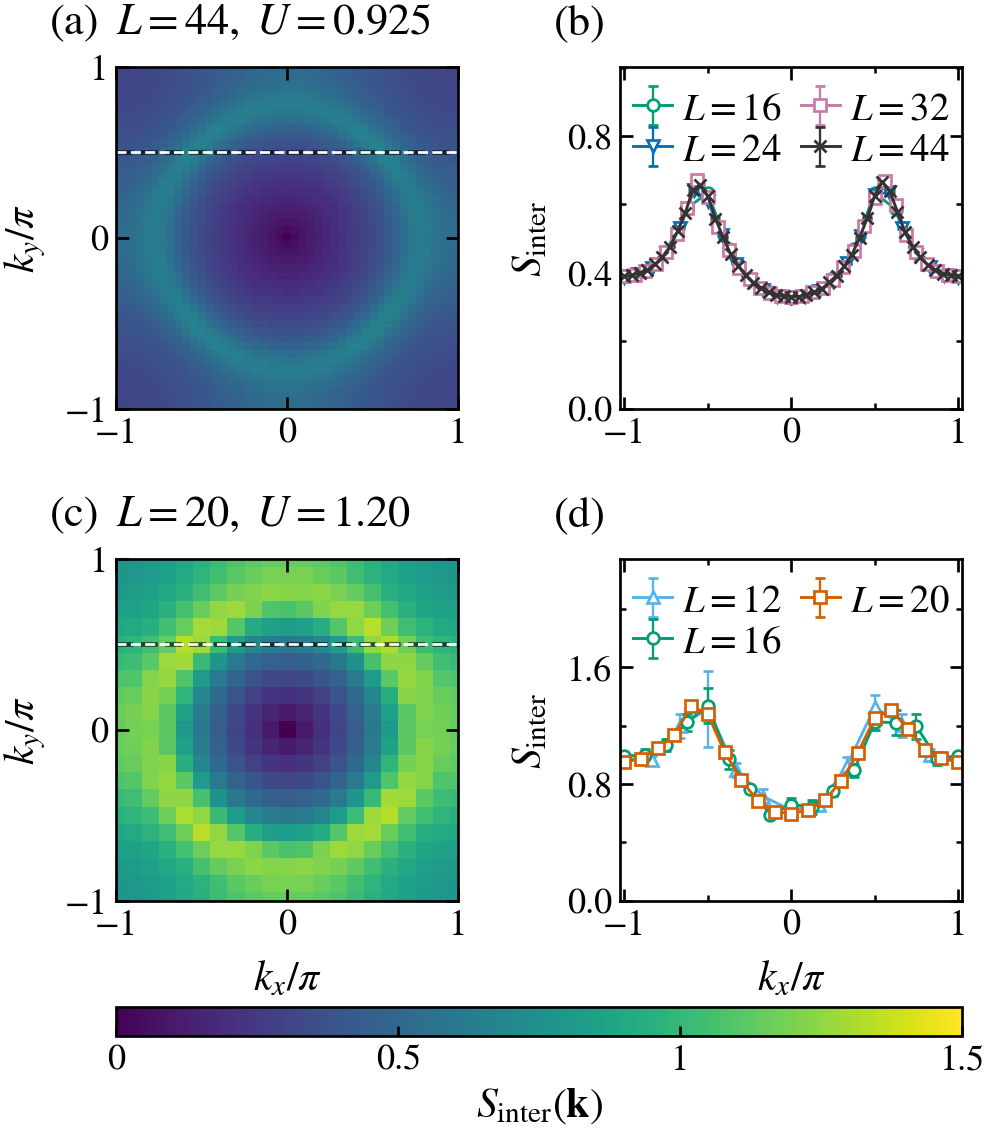

In [23]:
from matplotlib.colors import Normalize
from matplotlib.ticker import AutoMinorLocator, FormatStrFormatter, MaxNLocator

layout = dict(columnwidth_in=3.4, fig3_insert_width_in=3.4)
COLORS = {
    8: "#8e44ad",
    12: "#56B4E9",
    16: "#009E73",
    20: "#D55E00",
    24: "#0072B2",
    28: "#E69F00",
    32: "#CC79A7",
    36: "#8c564b",
    44: "#333333",
}
MARKERS = {8: "D", 12: "^", 16: "o", 20: "s", 24: "v", 28: "P", 32: "s", 36: "D", 44: "x"}
scale = layout["fig3_insert_width_in"] / (367.2904966001 / 72)
sizes = dict(axis_label=15 * scale, tick=13 * scale, legend=14 * scale, panel=16 * scale)
plt.rcdefaults()
plt.rcParams.update(
    {
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "font.size": sizes["legend"],
        "axes.labelsize": sizes["axis_label"],
        "axes.titlesize": sizes["panel"],
        "axes.linewidth": 0.65,
        "xtick.labelsize": sizes["tick"],
        "ytick.labelsize": sizes["tick"],
        "legend.fontsize": sizes["legend"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.facecolor": "white",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 0.65,
        "ytick.major.width": 0.65,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.minor.size": 1.5,
        "ytick.minor.size": 1.5,
    }
)
width = layout["columnwidth_in"]
left, right_margin, gap = (0.43, 0.15, 0.54)
panel_width = (width - left - right_margin - gap) / 2
bottom, top = (1.0, 0.3)
row_pitch = panel_width + 0.5
height = bottom + row_pitch + panel_width + top
fig = plt.figure(figsize=(width, height))
xright = left + panel_width + gap
map_max, cut_max = (0.0, 0.0)
for row in s10_rows:
    a = row["arrays"]
    row_cut_max = 0.0
    L = row["map_L"]
    map_max = max(map_max, float(a[f"L{L}_mean_sf"].max()))
    for L in row["Ls"]:
        m, e = (a[f"L{L}_mean_sf"], a[f"L{L}_stderr_sf"])
        cut_max = max(cut_max, float(np.max(m[:, L // 4] + e[:, L // 4])))
        row_cut_max = max(row_cut_max, float(np.max(m[:, L // 4] + e[:, L // 4])))
    row["cut_ymax"] = float(np.ceil(row_cut_max * 4) / 4 * 1.34)
color_max = 1.5
norm = Normalize(0, color_max)
cmap = plt.colormaps["viridis"]
for row_index, row in enumerate(s10_rows):
    y = bottom + (1 - row_index) * row_pitch
    a, map_L, u = (row["arrays"], row["map_L"], row["U"])
    axmap = fig.add_axes([left / width, y / height, panel_width / width, panel_width / height])
    axcut = fig.add_axes([xright / width, y / height, panel_width / width, panel_width / height])
    q = np.arange(-map_L // 2, map_L // 2 + 1) * 2 / map_L
    ix = np.arange(-map_L // 2, map_L // 2 + 1) % map_L
    shown = a[f"L{map_L}_mean_sf"][np.ix_(ix, ix)].T
    edges = np.arange(-map_L // 2 - 0.5, map_L // 2 + 1.5) * 2 / map_L
    mesh = axmap.pcolormesh(
        edges, edges, shown, cmap=cmap, norm=norm, shading="flat", rasterized=True
    )
    axmap.axhline(0.5, ls="--", color="black", lw=1.1, alpha=0.65)
    axmap.axhline(0.5, ls="--", color="white", lw=0.65)
    axmap.set(
        xlim=(-1, 1),
        ylim=(-1, 1),
        aspect="equal",
        xticks=[-1, 0, 1],
        yticks=[-1, 0, 1],
        ylabel="$k_y/\\pi$",
    )
    u_label = f"{u:.3f}" if u < 1 else f"{u:.2f}"
    axmap.set_title(f"$L={map_L},\\ U={u_label}$", loc="left", pad=8)
    for column, ax in enumerate((axmap, axcut)):
        letter = chr(97 + 2 * row_index + column)
        ax.annotate(
            f"({letter})",
            xy=(0, 1),
            xycoords="axes fraction",
            xytext=(-16, 8),
            textcoords="offset points",
            ha="left",
            va="baseline",
            fontsize=sizes["panel"],
            annotation_clip=False,
        )
    for L in row["Ls"]:
        k = np.arange(-L // 2, L // 2 + 1)
        ii, jj = (k % L, L // 4)
        qq = 2 * k / L
        mm, ee = (a[f"L{L}_mean_sf"][ii, jj], a[f"L{L}_stderr_sf"][ii, jj])
        axcut.errorbar(
            qq,
            mm,
            yerr=ee,
            color=COLORS[L],
            marker=MARKERS[L],
            mfc="white",
            ms=2.8,
            mew=0.65,
            lw=0.7,
            elinewidth=0.55,
            capsize=1.3,
            capthick=0.55,
            ls="-",
            label=f"$L={L}$",
        )
    axcut.set(
        xlim=(-1.025, 1.025),
        ylim=(0, row["cut_ymax"]),
        xticks=[-1, 0, 1],
        ylabel="$S_{\\mathrm{inter}}$",
    )
    if row_index == 1:
        axmap.set_xlabel("$k_x/\\pi$")
        axcut.set_xlabel("$k_x/\\pi$")
    axcut.yaxis.set_major_locator(MaxNLocator(3, min_n_ticks=3))
    axcut.xaxis.set_minor_locator(AutoMinorLocator(2))
    axcut.yaxis.set_minor_locator(AutoMinorLocator(2))
    axcut.legend(
        ncols=2,
        loc="upper center",
        frameon=False,
        handlelength=1.0,
        handletextpad=0.25,
        columnspacing=0.5,
        borderaxespad=0.25,
        labelspacing=0.15,
    )
    for ax in (axmap, axcut):
        ax.tick_params(which="both", direction="in", top=True, right=True, pad=2)
cax = fig.add_axes(
    [left / width, 0.55 / height, (width - left - right_margin) / width, 0.095 / height]
)
cb = fig.colorbar(mesh, cax=cax, orientation="horizontal")
cb.locator = MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10])
cb.update_ticks()
cb.ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))
cb.ax.tick_params(labelsize=sizes["tick"], length=2.5, pad=2)
cb.set_label("$S_{\\mathrm{inter}}(\\mathbf{k})$", size=sizes["axis_label"], labelpad=2)
fig.savefig("figures/FigS10.pdf", dpi=600, bbox_inches="tight", pad_inches=0.01)
fig.savefig("figures/FigS10.png", dpi=300, bbox_inches="tight", pad_inches=0.01)
display(fig)
plt.close(fig)


## S11: quarter filling

Load the scalar points and size-pair estimates. Fit only $\Delta L=8$
pairs with $L_{\rm eff}>20$.


In [24]:
quarter = pd.read_csv("data/s11_observables.csv", float_precision="round_trip")
quarter = quarter.sort_values(["observable", "L", "U"])
quarter_pair = quarter[quarter["observable"] == "R2e"]
quarter_quartet = quarter[quarter["observable"] == "C4"]
quarter_exponents = pd.read_csv("data/s11_exponents.csv", float_precision="round_trip")
quarter_exponents["L_eff"] = np.sqrt(quarter_exponents["L1"] * quarter_exponents["L2"])
quarter_fit_points = quarter_exponents[(quarter_exponents["DeltaL"] == 8) & (quarter_exponents["L_eff"] > 20)]
display_table(quarter.groupby("observable", sort=False).head(3)[
    ["L", "U", "observable", "value", "stderr"]])
display_table(quarter_fit_points[["L1", "L2", "L_eff", "nu", "nu_stderr", "eta", "eta_stderr"]])

L,U,observable,value,stderr
14,0.775,C4,0.002932,0.000023
14,0.780,C4,0.003164,0.000024
14,0.785,C4,0.003328,0.000033
10,0.775,M2,0.021357,0.000003
10,0.780,M2,0.021319,0.000003
10,0.785,M2,0.021287,0.000004
10,0.775,R2e,0.249553,0.000117
10,0.780,R2e,0.246690,0.000122
10,0.785,R2e,0.243938,0.000125


L1,L2,L_eff,nu,nu_stderr,eta,eta_stderr
18,26,21.633308,0.582196,0.017659,0.817198,0.002436
22,30,25.690465,0.668479,0.035681,0.806340,0.004173
26,34,29.732137,0.588032,0.036024,0.789330,0.006724
30,38,33.763886,0.674263,0.052578,0.776949,0.010946
34,42,37.788887,0.651109,0.053334,0.770886,0.019807


In [25]:
quarter_inverse_Leff = np.linspace(0, (1 / quarter_fit_points["L_eff"]).max(), 501)
quarter_powers = np.unique(np.r_[np.linspace(.5, 2, 1501), .758, 1.])
quarter_scans, quarter_fixed = {}, {}
quarter_summary = []
for observable in ["nu", "eta"]:
    scan = power_scan(quarter_fit_points, observable, quarter_powers, quarter_inverse_Leff)
    fit = fixed_power_fit(quarter_fit_points, observable, .758)
    quarter_scans[observable], quarter_fixed[observable] = scan, fit
    quarter_summary.append({"observable": observable, "n_fit_points": len(quarter_fit_points),
                            "fixed_power": .758, "intercept": fit["intercept"],
                            "conditional_stderr": fit["stderr"],
                            "envelope_low": scan["low"], "envelope_high": scan["high"]})
display_table(pd.DataFrame(quarter_summary))

observable,n_fit_points,fixed_power,intercept,conditional_stderr,envelope_low,envelope_high
nu,5,0.758,0.794566,0.105787,0.641633,1.039078
eta,5,0.758,0.693688,0.021218,0.605765,0.771039


Gray bands use the full
$p\in[.5,2]$ fitted-mean envelope; diamonds show fixed-$\omega$ intercepts
without error bars. The low-size points excluded from fitting remain visible.


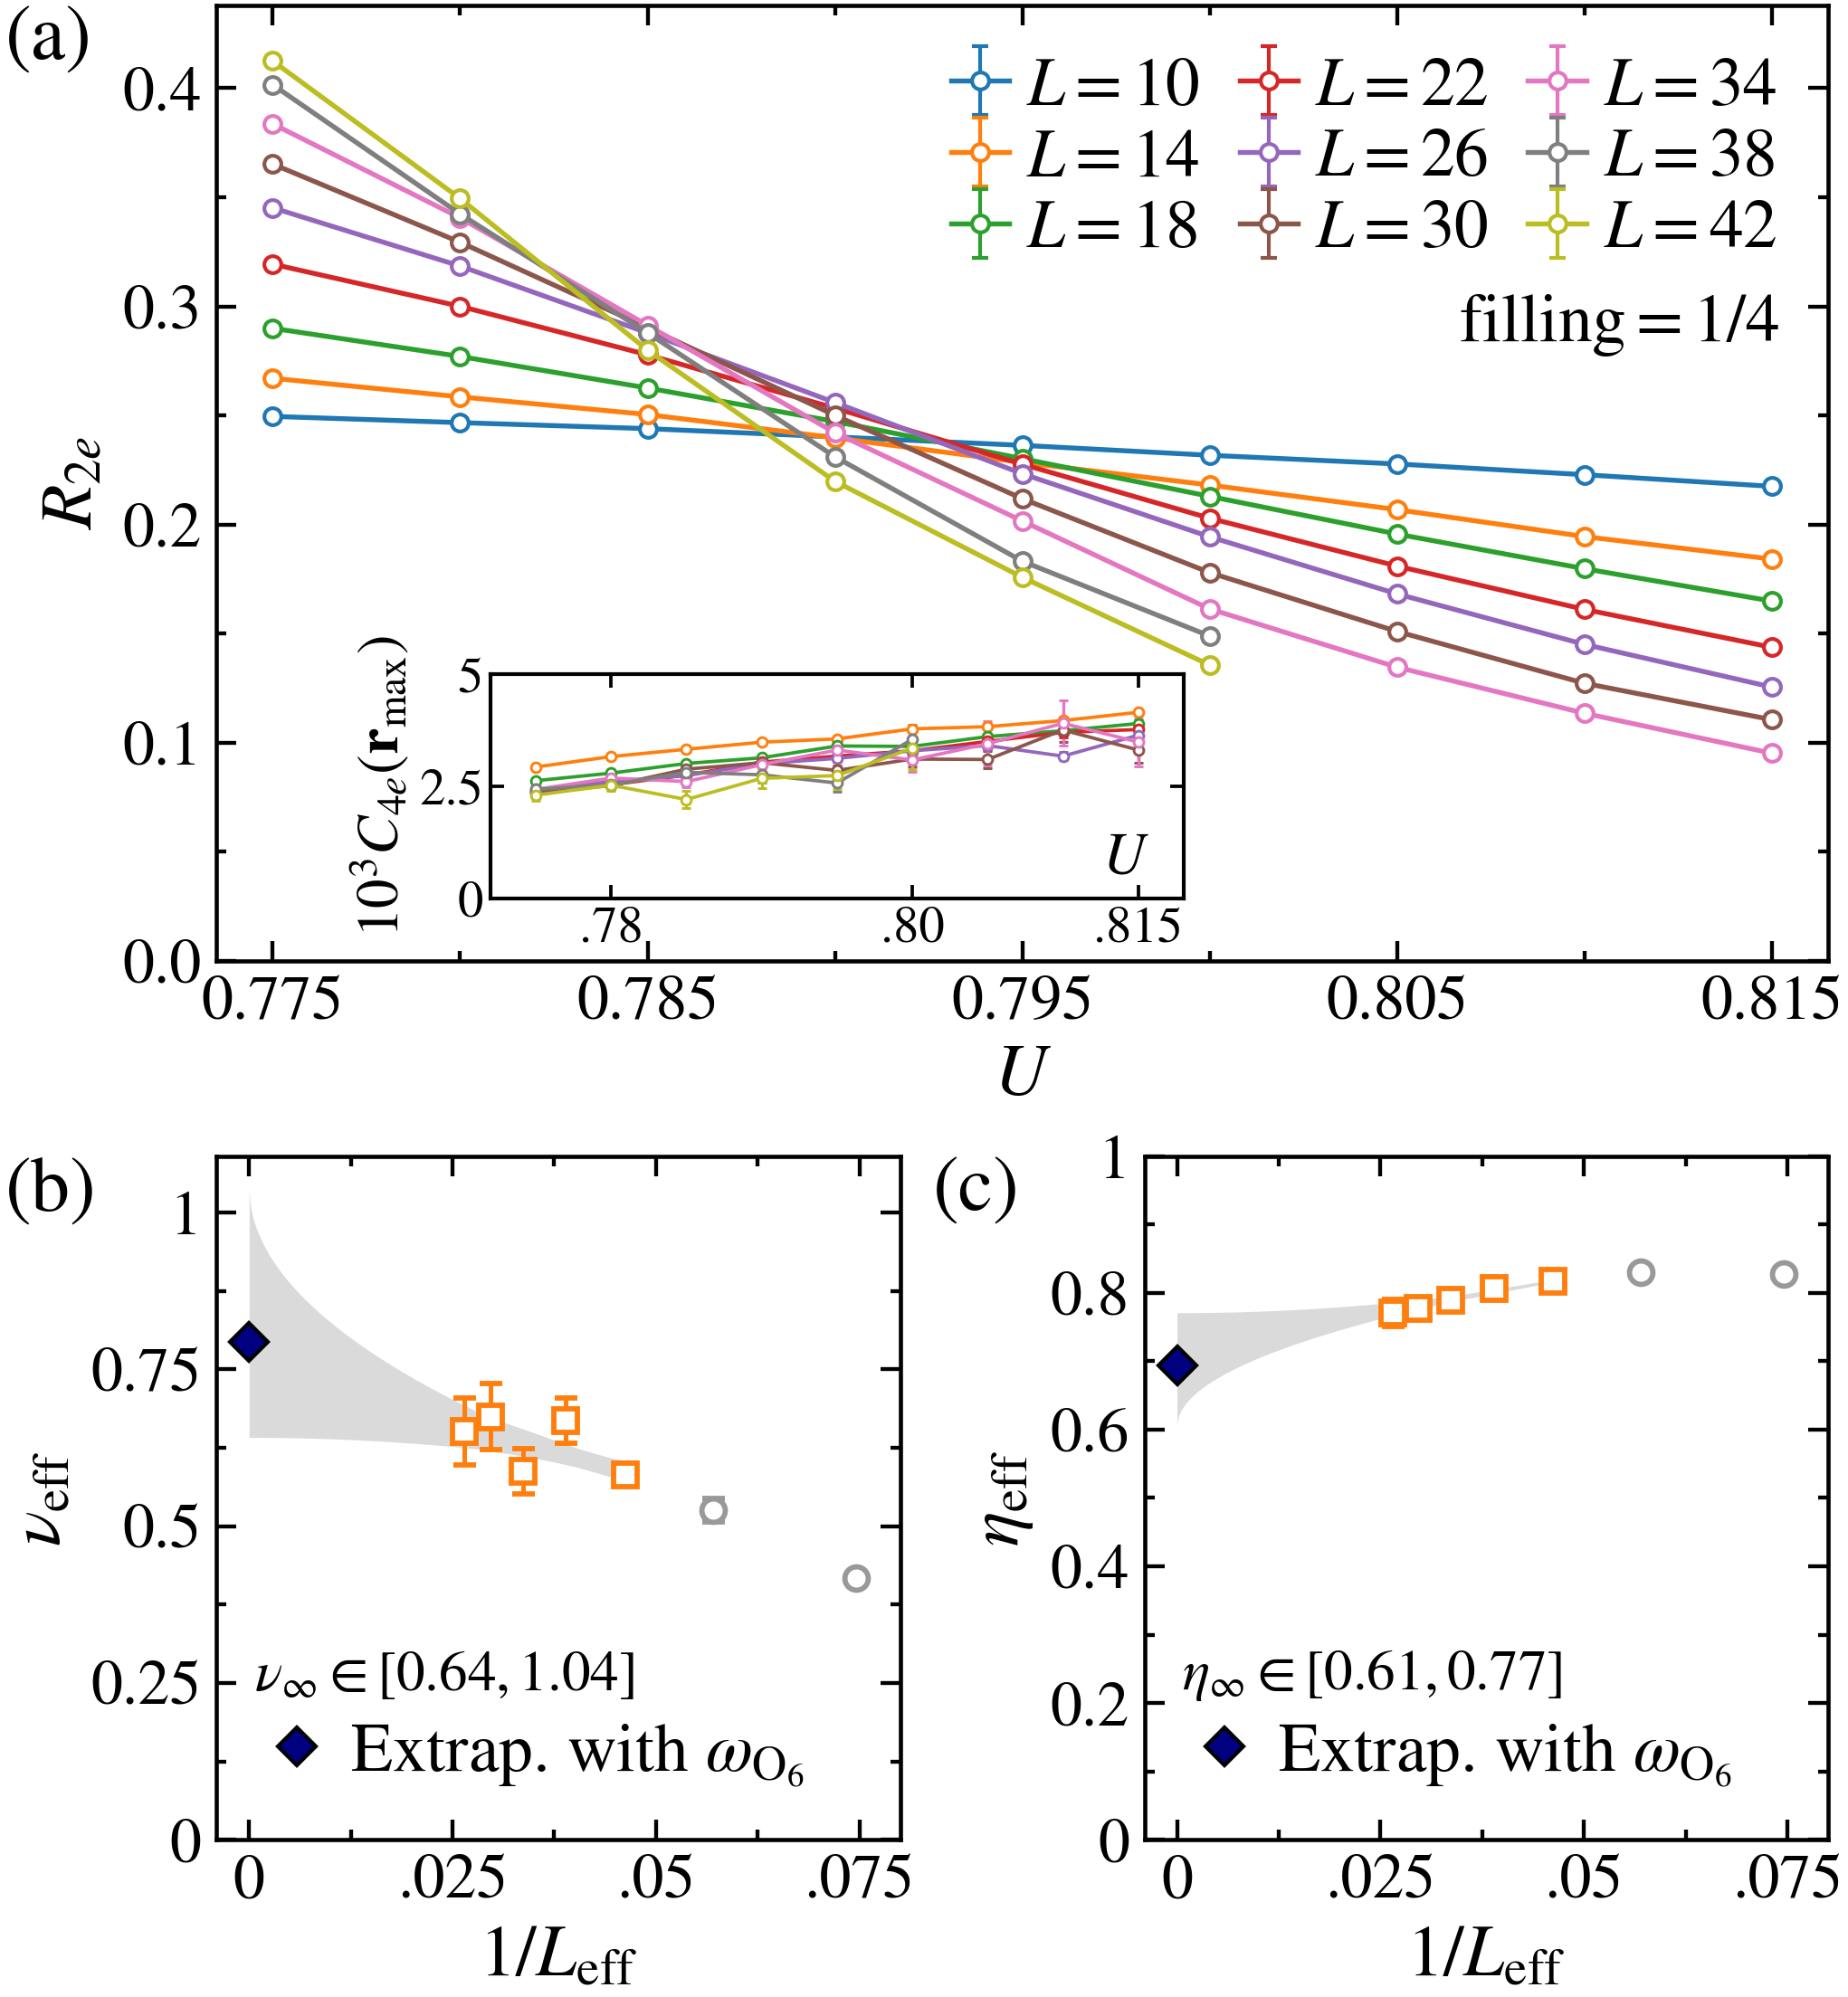

In [26]:
from matplotlib.ticker import AutoMinorLocator

plt.rcdefaults()
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "text.usetex": False,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
                     "font.size": 9.0657, "axes.labelsize": 9.71325,
                     "xtick.labelsize": 8.41815, "ytick.labelsize": 8.41815})
canvas_width = 3.4626773973605123
left, right_margin, gap = .45, .045, .45
available = canvas_width - left - right_margin
panel_width = (available - gap) / 2
bottom, row_gap, crossing_height = .39, .36, 1.76
crossing_bottom = bottom + panel_width + row_gap
canvas_height = crossing_bottom + crossing_height + .11
fig = plt.figure(figsize=(canvas_width, canvas_height), facecolor="white")
crossing = fig.add_axes([left / canvas_width, crossing_bottom / canvas_height,
                         available / canvas_width, crossing_height / canvas_height])
nu_ax = fig.add_axes([left / canvas_width, bottom / canvas_height,
                      panel_width / canvas_width, panel_width / canvas_height])
eta_ax = fig.add_axes([(left + panel_width + gap) / canvas_width, bottom / canvas_height,
                       panel_width / canvas_width, panel_width / canvas_height])
for ax, letter in zip([crossing, nu_ax, eta_ax], "abc"):
    ax.tick_params(which="both", direction="in", top=True, right=True, width=.52, pad=2)
    ax.tick_params(which="major", length=2.6)
    ax.tick_params(which="minor", length=1.3)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    for spine in ax.spines.values(): spine.set_linewidth(.55)
    ax.annotate(f"({letter})", (0, 1), xycoords="axes fraction", xytext=(-28, 0),
                textcoords="offset points", fontsize=10.3608, ha="left", va="top", annotation_clip=False)
for index, (L, group) in enumerate(quarter_pair.groupby("L", sort=True)):
    crossing.errorbar(group["U"], group["value"], yerr=group["stderr"], fmt="o-",
                       color=plt.cm.tab10.colors[index], mfc="white", ms=2.25, mew=.5,
                       lw=.65, elinewidth=.5, capsize=1.1, capthick=.5, label=rf"$L={L}$", zorder=3)
crossing.set(xlim=(.7735, .8165), ylim=(0, .438))
crossing.set_xlabel(r"$U$", labelpad=1.7)
crossing.set_ylabel(r"$R_{2e}$", labelpad=2)
crossing.set_xticks([.775, .785, .795, .805, .815])
crossing.set_yticks([0, .1, .2, .3, .4])
crossing.legend(loc="upper right", frameon=False, ncols=3, fontsize=9.0657,
                 handlelength=.85, handletextpad=.25, columnspacing=.58, labelspacing=.12, borderaxespad=.35)
crossing.text(.97, .70, r"$\mathrm{filling}=1/4$", transform=crossing.transAxes,
               ha="right", va="top", fontsize=9.0657)
inset = crossing.inset_axes([.17, .065, .43, .235])
for index, L in enumerate(sorted(quarter_pair["L"].unique())):
    if L == 10: continue
    group = quarter_quartet[quarter_quartet["L"] == L]
    inset.errorbar(group["U"], 1000 * group["value"], yerr=1000 * group["stderr"], fmt="o-",
                   color=plt.cm.tab10.colors[index], mfc="white", ms=1.3, mew=.35,
                   lw=.45, elinewidth=.4, capsize=.6, capthick=.4)
inset.set(xlim=(.772, .818), ylim=(0, 5))
inset.set_xticks([.78, .80, .815], [".78", ".80", ".815"])
inset.set_yticks([0, 2.5, 5], ["0", "2.5", "5"])
inset.set_ylabel(r"$10^3 C_{4e}(\mathbf{r}_{\max})$", fontsize=7.8, labelpad=1)
inset.text(.95, .055, r"$U$", transform=inset.transAxes, ha="right", va="bottom", fontsize=7.8)
inset.tick_params(which="both", direction="in", top=True, right=True,
                   labelsize=6.8, width=.45, length=1.8, pad=1)
for spine in inset.spines.values(): spine.set_linewidth(.5)
for ax, observable in [(nu_ax, "nu"), (eta_ax, "eta")]:
    for included, color, marker in [(True, "#ff7f0e", "s"), (False, ".60", "o")]:
        group = quarter_exponents[(quarter_exponents["L_eff"] > 20) == included]
        ax.errorbar(1 / group["L_eff"], group[observable], yerr=group[observable + "_stderr"],
                    fmt=marker, color=color, mfc="white", ms=3.1, mew=.7,
                    elinewidth=.6, capsize=1.5, capthick=.6, zorder=4)
    scan, fit = quarter_scans[observable], quarter_fixed[observable]
    ax.fill_between(quarter_inverse_Leff, scan["lower"], scan["upper"],
                    color=".82", alpha=.8, linewidth=0, zorder=1)
    ax.plot(0, fit["intercept"], marker="D", linestyle="none", color="k", mfc="navy", ms=3.6,
            mew=.5, label=r"Extrap. with $\omega_{\mathrm{O}_6}$", zorder=5)
    ax.set(xlim=(-.004, .080), ylim=(0, 1.09 if observable == "nu" else 1))
    ax.set_xticks([0, .025, .05, .075], ["0", ".025", ".05", ".075"])
    if observable == "nu": ax.set_yticks([0, .25, .5, .75, 1], ["0", "0.25", "0.5", "0.75", "1"])
    else: ax.set_yticks([0, .2, .4, .6, .8, 1], ["0", "0.2", "0.4", "0.6", "0.8", "1"])
    ax.set_xlabel(r"$1/L_{\mathrm{eff}}$", labelpad=2)
    ax.set_ylabel(rf"$\{observable}_{{\mathrm{{eff}}}}$", labelpad=2)
    ax.text(.055, .20, rf"$\{observable}_\infty\in[{scan['low']:.2f},{scan['high']:.2f}]$",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=7.6)
    ax.legend(loc="lower left", frameon=False, fontsize=9.0657, handlelength=.85,
              handletextpad=.35, borderaxespad=.35, labelspacing=.15)
fig.savefig("figures/FigS11.pdf", bbox_inches="tight", pad_inches=.01, facecolor="white")
fig.savefig("figures/FigS11.png", dpi=600, bbox_inches="tight", pad_inches=.01, facecolor="white")
plt.show()
plt.close(fig)

## Figure S12: quarter-filled density correlations

The maps show fourfold-symmetrized interflavor correlations. The peak table
supplies $\max S/L^2$ and its reported error. Lines connect measured sizes;
no scaling fit is performed. Black diamonds show the late series.
Fourfold averaging does not establish orientation mixing, and the
strong-coupling late-series drift remains.


In [27]:
s12_data = pd.read_csv("data/s12_value_error.csv", float_precision="round_trip")
s12_peaks = pd.read_csv("data/s12_maxima.csv", float_precision="round_trip")
display_table(s12_data[["U", "space", "x", "y", "value", "error"]].head())
display_table(s12_peaks[["U", "L", "series", "value", "error"]])


s12_grid_sizes = (
    s12_data.groupby(["U", "L", "space"], sort=True).size().rename("rows").reset_index()
)
display_table(s12_grid_sizes)


U,space,x,y,value,error
0.8,momentum,0.0,0.000,-4.004089e-14,6.957876e-17
0.8,momentum,0.0,0.125,1.173002e-01,1.031562e-04
0.8,momentum,0.0,0.250,1.893478e-01,1.042336e-04
0.8,momentum,0.0,0.375,2.611696e-01,1.350025e-04
0.8,momentum,0.0,0.500,3.428307e-01,1.374060e-04


U,L,series,value,error
0.8,8,main,0.036716,0.000060
0.9,8,main,0.091845,0.000672
0.8,12,main,0.012319,0.000014
0.9,12,main,0.096096,0.000714
0.8,16,main,0.010203,0.000024
0.9,16,main,0.097497,0.000150
0.8,20,main,0.006887,0.000031
0.9,20,main,0.091101,0.001570
0.8,20,late,0.006836,0.000057
0.9,20,late,0.095797,0.000395


U,L,space,rows
0.8,16,momentum,256
0.8,16,real,256
0.9,16,momentum,256
0.9,16,real,256


In [28]:
s12_records = []
for u, interaction in s12_data.groupby("U", sort=True):
    maps = {}
    for space, grid in interaction.groupby("space"):
        grid = grid.sort_values(["ix", "iy"])
        maps[space] = (
            grid["value"].to_numpy().reshape(16, 16),
            grid["error"].to_numpy().reshape(16, 16),
        )
    s12_records.append(
        dict(
            U=u,
            mean_c=maps["real"][0],
            se_c=maps["real"][1],
            mean_s=maps["momentum"][0],
            se_s=maps["momentum"][1],
        )
    )
s12_maxima = s12_peaks.to_dict("records")
s12_late_rows = [row for row in s12_maxima if row["series"] == "late"]


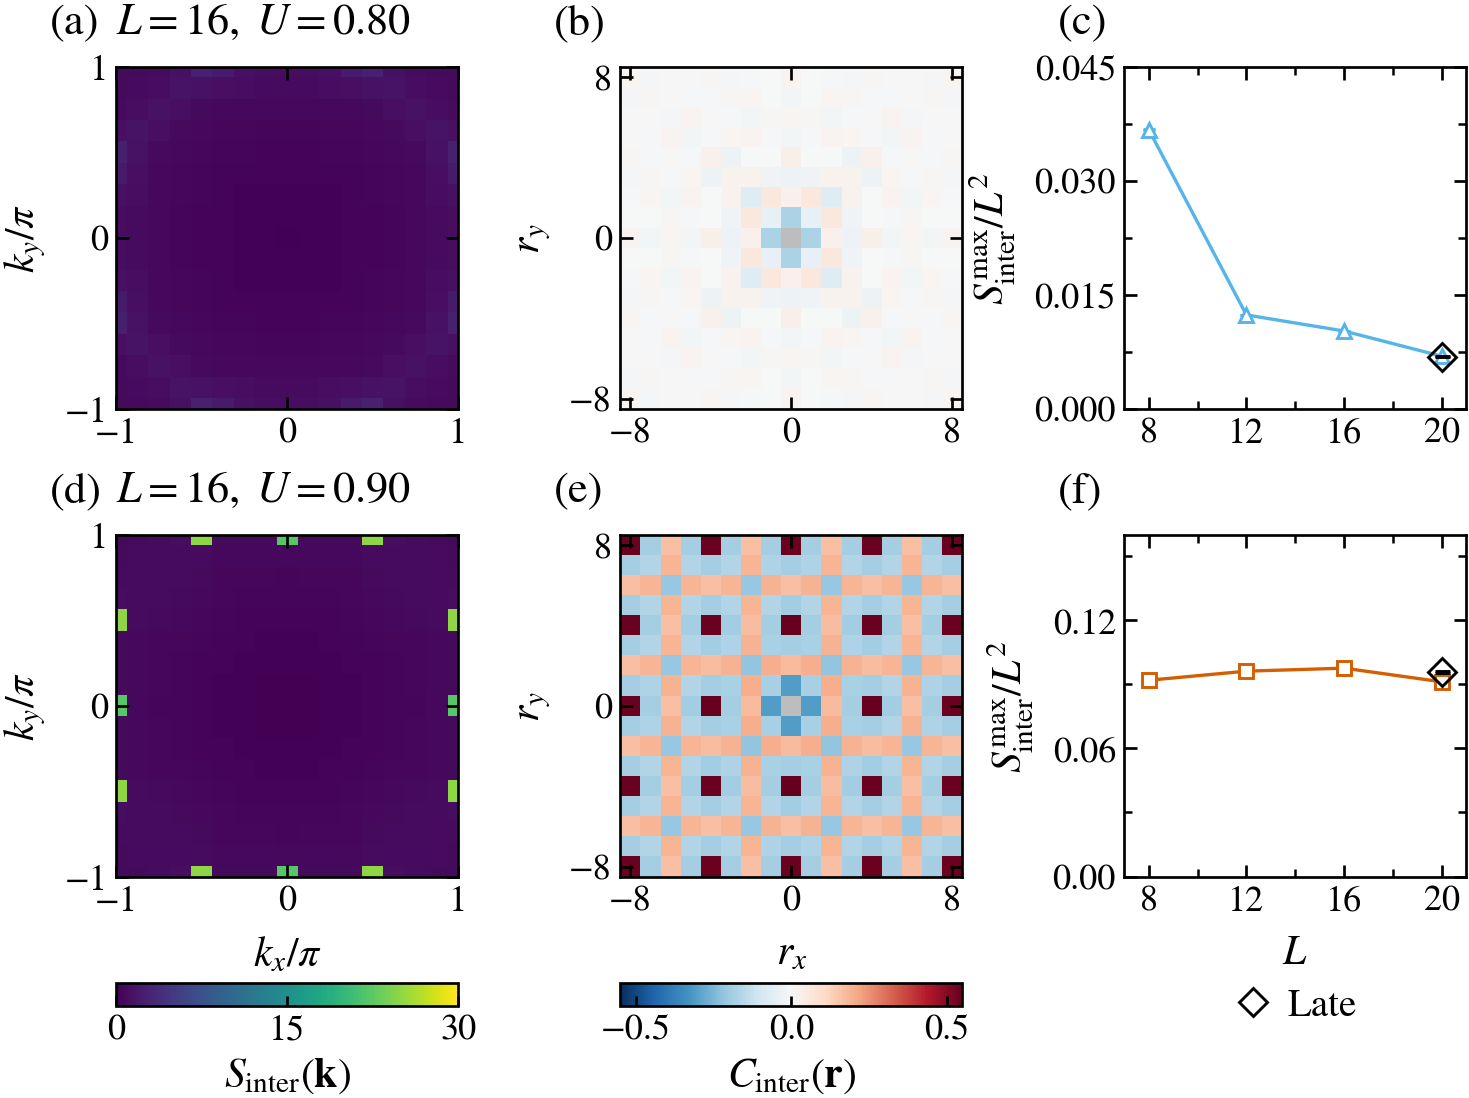

In [29]:
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

WIDTH = 5.08
L = 16
SIZES = (8, 12, 16, 20)
scale = 3.4 / (367.2904966001 / 72.0)
sizes = dict(axis_label=15 * scale, tick=13 * scale, legend=14 * scale, panel=16 * scale)
plt.rcdefaults()
plt.rcParams.update(
    {
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "font.size": sizes["legend"],
        "axes.labelsize": sizes["axis_label"],
        "axes.titlesize": sizes["panel"],
        "axes.linewidth": 0.65,
        "xtick.labelsize": sizes["tick"],
        "ytick.labelsize": sizes["tick"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.facecolor": "white",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 0.65,
        "ytick.major.width": 0.65,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
    }
)
left, gap, right_margin = (0.43, 0.54, 0.15)
panel = (WIDTH - left - 2 * gap - right_margin) / 3.0
bottom, pitch, top = (0.83, panel + 0.42, 0.32)
height = bottom + pitch + panel + top
fig = plt.figure(figsize=(WIDTH, height))
s_limit = 30.0
offsite = np.ones((L, L), dtype=bool)
offsite[0, 0] = False
c_limit = float(
    np.ceil(max((np.abs(r["mean_c"][offsite]).max() for r in s12_records)) * 20.0) / 20.0
)
snorm = Normalize(vmin=0, vmax=s_limit)
cnorm = TwoSlopeNorm(vmin=-c_limit, vcenter=0, vmax=c_limit)
ccmap = plt.colormaps["RdBu_r"].copy()
ccmap.set_bad("#bdbdbd")
coordinates = np.arange(-L // 2, L // 2 + 1)
indices = coordinates % L
real_edges = np.arange(-L // 2 - 0.5, L // 2 + 1.5)
momentum_edges = real_edges * 2.0 / L
for row, record in enumerate(s12_records):
    y = bottom + (1 - row) * pitch
    ax_s = fig.add_axes([left / WIDTH, y / height, panel / WIDTH, panel / height])
    ax_c = fig.add_axes([(left + panel + gap) / WIDTH, y / height, panel / WIDTH, panel / height])
    ax_max = fig.add_axes(
        [(left + 2 * (panel + gap)) / WIDTH, y / height, panel / WIDTH, panel / height]
    )
    shown_s = record["mean_s"][np.ix_(indices, indices)].T
    shown_c = record["mean_c"][np.ix_(indices, indices)].T
    mask = np.zeros_like(shown_c, dtype=bool)
    mask[L // 2, L // 2] = True
    smesh = ax_s.pcolormesh(
        momentum_edges,
        momentum_edges,
        shown_s,
        norm=snorm,
        cmap="viridis",
        shading="flat",
        rasterized=True,
    )
    cmesh = ax_c.pcolormesh(
        real_edges,
        real_edges,
        np.ma.array(shown_c, mask=mask),
        norm=cnorm,
        cmap=ccmap,
        shading="flat",
        rasterized=True,
    )
    ax_s.set(
        xlim=(-1, 1),
        ylim=(-1, 1),
        xticks=[-1, 0, 1],
        yticks=[-1, 0, 1],
        aspect="equal",
        ylabel="$k_y/\\pi$",
    )
    ax_c.set(
        xlim=(real_edges[0], real_edges[-1]),
        ylim=(real_edges[0], real_edges[-1]),
        xticks=[-8, 0, 8],
        yticks=[-8, 0, 8],
        aspect="equal",
        ylabel="$r_y$",
    )
    ax_s.set_title(f"$L={L},\\ U={record['U']:.2f}$", loc="left", pad=8)
    peaks = sorted(
        (r for r in s12_maxima if r["U"] == record["U"] and r["series"] == "main"),
        key=lambda r: r["L"],
    )
    color = "#56B4E9" if row == 0 else "#D55E00"
    marker = "^" if row == 0 else "s"
    ax_max.errorbar(
        [r["L"] for r in peaks],
        [r["value"] for r in peaks],
        yerr=[r["error"] for r in peaks],
        color=color,
        marker=marker,
        mfc="white",
        ms=3.2,
        mew=0.7,
        lw=0.8,
        elinewidth=0.6,
        capsize=1.5,
        capthick=0.6,
    )
    late = next((r for r in s12_late_rows if r["U"] == record["U"]))
    ax_max.errorbar(
        [20],
        [late["value"]],
        yerr=[late["error"]],
        color="black",
        marker="D",
        mfc="none",
        ms=4.6,
        mew=0.7,
        ls="none",
        elinewidth=0.65,
        capsize=1.8,
        capthick=0.65,
        zorder=5,
    )
    ax_max.set(
        xlim=(7, 21),
        xticks=list(SIZES),
        ylim=(0, 0.045) if row == 0 else (0, 0.16),
        ylabel="$S_{\\mathrm{inter}}^{\\max}/L^2$",
    )
    ax_max.yaxis.set_major_locator(MaxNLocator(3, min_n_ticks=3))
    ax_max.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax_max.yaxis.set_minor_locator(AutoMinorLocator(2))
    if row == 1:
        ax_s.set_xlabel("$k_x/\\pi$")
        ax_c.set_xlabel("$r_x$")
        ax_max.set_xlabel("$L$")
    for column, ax in enumerate((ax_s, ax_c, ax_max)):
        letter = chr(97 + 3 * row + column)
        ax.annotate(
            f"({letter})",
            xy=(0, 1),
            xycoords="axes fraction",
            xytext=(-16, 8),
            textcoords="offset points",
            ha="left",
            va="baseline",
            fontsize=sizes["panel"],
            annotation_clip=False,
        )
        ax.tick_params(which="both", top=True, right=True, pad=2)
for x, mesh, ticks, label in (
    (left, smesh, [0, s_limit / 2.0, s_limit], "$S_{\\mathrm{inter}}(\\mathbf{k})$"),
    (left + panel + gap, cmesh, [-0.5, 0, 0.5], "$C_{\\mathrm{inter}}(\\mathbf{r})$"),
):
    cax = fig.add_axes([x / WIDTH, 0.4 / height, panel / WIDTH, 0.075 / height])
    bar = fig.colorbar(mesh, cax=cax, orientation="horizontal", ticks=ticks)
    bar.ax.tick_params(labelsize=sizes["tick"], length=2.5, pad=2)
    bar.set_label(label, size=sizes["axis_label"], labelpad=2)
late_handle = Line2D(
    [], [], color="black", marker="D", mfc="none", ms=4.6, mew=0.7, ls="none", label="Late"
)
fig.legend(
    handles=[late_handle],
    loc="center",
    bbox_to_anchor=((left + 2 * (panel + gap) + panel / 2.0) / WIDTH, 0.4 / height),
    frameon=False,
    fontsize=sizes["legend"],
    handlelength=1.0,
    handletextpad=0.4,
)
fig.savefig("figures/FigS12.pdf", dpi=600, bbox_inches="tight", pad_inches=0.01)
fig.savefig("figures/FigS12.png", dpi=300, bbox_inches="tight", pad_inches=0.01)
display(fig)
plt.close(fig)
